<a href="https://colab.research.google.com/github/huseyinTozluyurt/Flyrank-Internship-MachineLearning/blob/main/notebooks/ContentRefreshRecommendationEngine/FlyRank_Content_Refresh_Recommendation_Engine_Final_Integrated_Draft.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# FlyRank — Content Refresh Recommendation Engine

## Final integrated workflow

This notebook consolidates Stage 1 (data validation and transparent benchmark), Stage 2 (coverage-aware LambdaRank evaluation), Stage 3 (intervention/outcome tracking), and Stage 4 (release readiness and monitoring). The central correction is to keep **held-out evaluation** separate from the **production candidate queue**: evaluation rows are not reused as the operational queue.


# 0. Repository setup

In Colab, clone the FlyRank starter repository and install its declared dependencies. Outside Colab, locate the repository root by checking for `requirements.txt` and `data/raw`. The full-release warehouse path is configured in the next section; the starter CSV is optional and is not required for the DuckDB/Hugging Face workflow.


In [1]:
import os, sys, subprocess
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
REPO_URL = "https://github.com/flyrank-bih/flyrank-ml-internship-starter"
REPO_DIR = "flyrank-ml-internship-starter"

if IN_COLAB:
    if not Path(REPO_DIR).is_dir():
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, REPO_DIR], check=True)
    os.chdir(REPO_DIR)
    requirements_path = Path("requirements.txt")
    if not requirements_path.exists():
        raise FileNotFoundError(f"requirements.txt not found under {Path.cwd()}")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", str(requirements_path)], check=True)
else:
    current = Path.cwd().resolve()
    repo_root = None
    for candidate in [current, *current.parents]:
        if (candidate / "requirements.txt").is_file() and (candidate / "data" / "raw").is_dir():
            repo_root = candidate
            break
    if repo_root is None:
        raise FileNotFoundError(
            "Could not locate repository root. Open this notebook from the FlyRank repository, "
            "or run it in Colab so the repository can be cloned automatically."
        )
    os.chdir(repo_root)

print("Working directory:", Path.cwd())
starter_csv = Path("data/raw/content_refresh_anonymized.csv")
if starter_csv.exists():
    print("Optional starter CSV found:", starter_csv)
else:
    print("Optional starter CSV not found; continuing with the configured full-release DuckDB/Hugging Face workflow.")


Working directory: /content/flyrank-ml-internship-starter
Optional starter CSV found: data/raw/content_refresh_anonymized.csv


## 1. Authenticate to Hugging Face

In Colab, add `HF_TOKEN` under **Secrets** and enable notebook access. The fallback prompt is hidden input. Never hard-code the token or share it in chat.

In [2]:
import os
from getpass import getpass

HF_TOKEN = os.environ.get("HF_TOKEN")
if not HF_TOKEN:
    try:
        from google.colab import userdata
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None
if not HF_TOKEN:
    HF_TOKEN = getpass("Hugging Face token (input hidden): ")
if not HF_TOKEN:
    raise RuntimeError("HF_TOKEN is required to access the private dataset.")
print("Hugging Face token loaded.")


Hugging Face token (input hidden): ··········
Hugging Face token loaded.


In [3]:
import duckdb
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.impute import SimpleImputer
from sklearn.model_selection import GroupShuffleSplit
from lightgbm import LGBMRanker
import joblib
import warnings
import json
from pathlib import Path

con = duckdb.connect()
safe_token = HF_TOKEN.replace("'", "''")
con.execute(f"CREATE OR REPLACE SECRET hf (TYPE huggingface, TOKEN '{safe_token}')")

REL = "hf://datasets/FlyRank/internship-warehouse"
TABLES = {
    "dim_clients": f"read_parquet('{REL}/dim_clients.parquet')",
    "dim_content": f"read_parquet('{REL}/dim_content.parquet')",
    "fact_daily": f"read_parquet('{REL}/fact_content_daily_performance/**/*.parquet')",
    "fact_daily_sample": f"read_parquet('{REL}/fact_content_daily_performance_sample.parquet')",
    "fact_query_90d": f"read_parquet('{REL}/fact_content_query_90d.parquet')",
}
print("DuckDB connected; warehouse paths configured.")


DuckDB connected; warehouse paths configured.


## 2. Inspect schema and date coverage

The notebook discovers optional metadata/query columns at runtime. It requires the identifiers, report date, GSC availability flag, impressions, clicks, and average position. If the warehouse schema differs, the notebook stops instead of silently substituting fields.

In [4]:
schemas = {}
for table_name, source_sql in TABLES.items():
    try:
        schemas[table_name] = con.execute(f"DESCRIBE SELECT * FROM {source_sql}").df()
        print(f"{table_name}: {len(schemas[table_name])} columns")
    except Exception as exc:
        if table_name in {"dim_content", "fact_query_90d", "dim_clients", "fact_daily_sample"}:
            warnings.warn(f"Optional table {table_name} could not be inspected: {exc}")
        else:
            raise

daily_columns = set(schemas["fact_daily"]["column_name"])
display(schemas["fact_daily"])
required = {
    "report_date", "client_hash_id", "content_hash_id",
    "gsc_data_available", "gsc_impressions", "gsc_clicks", "gsc_avg_position"
}
missing = required - daily_columns
if missing:
    raise ValueError(f"Required columns missing from fact_daily: {sorted(missing)}")

date_coverage = con.execute(f'''
SELECT MIN(report_date) AS min_report_date,
       MAX(report_date) AS max_report_date,
       COUNT(*) AS raw_rows,
       COUNT(DISTINCT client_hash_id) AS clients,
       COUNT(DISTINCT content_hash_id) AS content_ids
FROM {TABLES["fact_daily"]}
''').df()
display(date_coverage)


dim_clients: 9 columns
dim_content: 26 columns
fact_daily: 31 columns
fact_daily_sample: 31 columns
fact_query_90d: 21 columns


,column_name,column_type,null,key,default,extra
0,report_date,DATE,YES,None,None,None
1,client_hash_id,VARCHAR,YES,None,None,None
2,content_hash_id,VARCHAR,YES,None,None,None
3,client_has_gsc,BOOLEAN,YES,None,None,None
4,client_has_ga4,BOOLEAN,YES,None,None,None
5,gsc_data_available,BOOLEAN,YES,None,None,None
6,ga4_data_available,BOOLEAN,YES,None,None,None
7,gsc_impressions,BIGINT,YES,None,None,None
8,gsc_clicks,BIGINT,YES,None,None,None
9,gsc_sum_position,BIGINT,YES,None,None,None


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,min_report_date,max_report_date,raw_rows,clients,content_ids
0,2025-01-27,2026-06-30,78835655,70,427292


## 3. Audit GSC availability, missing measurements, and duplicate keys — optimized

The previous version scanned the remote Parquet source separately for the availability audit, duplicate-key audit, and per-client coverage audit. The duplicate-key query also performed a costly `COUNT(DISTINCT struct)` across the full recent window.

This version:
1. Reads only the columns needed for these checks.
2. Creates one temporary, 120-day audit table and reuses it for all diagnostics.
3. Checks duplicate keys in two passes: first count duplicate keys; then check conflicting values only within duplicated keys.
4. Avoids a full per-client date-distinct report by summarizing coverage from the cached audit table.

The initial maximum-date lookup still requires DuckDB to inspect the remote dataset. If the source is partitioned by date, partition pruning may further improve performance; verify this from the dataset's actual file layout.

In [5]:
# Configure DuckDB conservatively for Colab. Set memory_limit below the runtime's RAM.
import os
from time import perf_counter

duckdb_threads = max(1, (os.cpu_count() or 2) - 1)
con.execute(f"SET threads = {duckdb_threads}")
con.execute("SET preserve_insertion_order = false")
# If this runtime has 12+ GB RAM, 8GB is a reasonable starting point.
# Lower this value if the runtime has less memory.
con.execute("SET memory_limit = '8GB'")

audit_started = perf_counter()

# Determine the latest date once. The following table is then reused for all audits.
audit_end_date = con.execute(
    f"SELECT MAX(report_date) FROM {TABLES['fact_daily']}"
).fetchone()[0]
if audit_end_date is None:
    raise ValueError("No report_date values were found in fact_daily.")

print("Latest report date:", audit_end_date)
print("DuckDB threads:", duckdb_threads)

# Use a narrow projection and retain source rows for the duplicate checks.
# Do not DISTINCT here: we need to distinguish identical duplicates from conflicts.
con.execute("DROP TABLE IF EXISTS stage21_audit_daily")
con.execute(f"""
CREATE TEMP TABLE stage21_audit_daily AS
SELECT
    report_date,
    client_hash_id,
    content_hash_id,
    gsc_data_available,
    gsc_impressions,
    gsc_clicks,
    gsc_avg_position
FROM {TABLES["fact_daily"]}
WHERE report_date > ? - INTERVAL 120 DAY
""", [audit_end_date])

print(f"Cached 120-day audit rows: {con.execute('SELECT COUNT(*) FROM stage21_audit_daily').fetchone()[0]:,}")
print(f"Initial scan and cache time: {perf_counter() - audit_started:.1f} seconds")

# Availability and missingness summary from the cached table (no remote Parquet scan).
availability_audit = con.execute("""
SELECT
    CASE
      WHEN gsc_data_available IS TRUE THEN 'available_true'
      WHEN gsc_data_available IS FALSE THEN 'available_false'
      ELSE 'availability_null'
    END AS gsc_availability_status,
    COUNT(*) AS rows,
    COUNT(*) FILTER (WHERE gsc_impressions IS NULL) AS impressions_null_rows,
    COUNT(*) FILTER (WHERE gsc_clicks IS NULL) AS clicks_null_rows,
    COUNT(*) FILTER (WHERE gsc_avg_position IS NULL) AS position_null_rows,
    COUNT(*) FILTER (WHERE gsc_impressions = 0) AS explicit_zero_impression_rows,
    COUNT(*) FILTER (WHERE gsc_data_available IS TRUE AND gsc_impressions IS NULL)
        AS available_but_impressions_missing
FROM stage21_audit_daily
GROUP BY 1
ORDER BY 1
""").df()
display(availability_audit)

# First pass: find duplicate key groups without expensive distinct-struct aggregation.
duplicate_groups = con.execute("""
CREATE OR REPLACE TEMP TABLE stage21_duplicate_keys AS
SELECT
    report_date, client_hash_id, content_hash_id, COUNT(*) AS n_rows
FROM stage21_audit_daily
GROUP BY report_date, client_hash_id, content_hash_id
HAVING COUNT(*) > 1
""")
duplicate_key_counts = con.execute("""
SELECT
    COUNT(*) AS duplicate_key_groups,
    COALESCE(SUM(n_rows - 1), 0) AS excess_rows_in_duplicate_groups
FROM stage21_duplicate_keys
""").df()

# Second pass: compare values only for duplicate keys. Hash the selected GSC fields
# to avoid materializing a large DISTINCT struct; nulls are represented explicitly.
duplicate_conflicts = con.execute("""
WITH versions AS (
    SELECT
        d.report_date,
        d.client_hash_id,
        d.content_hash_id,
        COUNT(DISTINCT hash(
            coalesce(CAST(d.gsc_data_available AS VARCHAR), '<NULL>'),
            coalesce(CAST(d.gsc_impressions AS VARCHAR), '<NULL>'),
            coalesce(CAST(d.gsc_clicks AS VARCHAR), '<NULL>'),
            coalesce(CAST(d.gsc_avg_position AS VARCHAR), '<NULL>')
        )) AS distinct_gsc_versions
    FROM stage21_audit_daily d
    INNER JOIN stage21_duplicate_keys k
      USING (report_date, client_hash_id, content_hash_id)
    GROUP BY 1, 2, 3
)
SELECT
    COUNT(*) FILTER (WHERE distinct_gsc_versions = 1) AS exact_duplicate_key_groups,
    COUNT(*) FILTER (WHERE distinct_gsc_versions > 1) AS conflicting_duplicate_key_groups
FROM versions
""").df()

duplicate_key_audit = duplicate_key_counts.join(duplicate_conflicts)
display(duplicate_key_audit)

# Per-client availability summary from the same cached table.
availability_by_client = con.execute("""
SELECT
    client_hash_id,
    COUNT(DISTINCT report_date) AS dates_with_rows,
    COUNT(DISTINCT CASE WHEN gsc_data_available IS TRUE THEN report_date END) AS dates_gsc_available,
    COUNT(DISTINCT CASE WHEN gsc_data_available IS FALSE THEN report_date END) AS dates_gsc_unavailable,
    COUNT(DISTINCT CASE WHEN gsc_data_available IS NULL THEN report_date END) AS dates_gsc_status_unknown
FROM stage21_audit_daily
GROUP BY client_hash_id
ORDER BY dates_gsc_available DESC
""").df()
display(availability_by_client.head(20))
print(f"Section 3 audit completed in {perf_counter() - audit_started:.1f} seconds.")


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Latest report date: 2026-06-30
DuckDB threads: 1


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Cached 120-day audit rows: 43,095,413
Initial scan and cache time: 345.6 seconds


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

...

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,duplicate_key_groups,excess_rows_in_duplicate_groups,exact_duplicate_key_groups,conflicting_duplicate_key_groups
0,6390,6390.0,6390,0


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,client_hash_id,dates_with_rows,dates_gsc_available,dates_gsc_unavailable,dates_gsc_status_unknown
0,client_65de48885f4ef01b,120,120,120,0
1,client_c182d11e4862a37d,120,120,120,0
2,client_400c21c81c8b46ef,120,120,120,0
3,client_08a6a72ff48e62c0,120,120,120,0
4,client_23a62021009f63c4,120,120,120,0
5,client_62f4a7e64f5e0096,120,120,120,0
6,client_3ffa76342f366962,120,120,120,0
7,client_9958f0a7ae1df715,120,120,120,0
8,client_73cda7b4e4f265ea,120,120,120,0
9,client_3197e6291363b4db,120,120,115,0


Section 3 audit completed in 403.5 seconds.


### Coverage policy

For target labels, a client-content pair must have at least `MIN_TARGET_OBSERVED_DAYS` distinct days with `gsc_data_available = TRUE` and non-null impressions in each 30-day target window. Missing target impressions are not filled with zero. Exact repeated GSC observations are flagged and can be deduplicated during feature aggregation; conflicting observations for the same client/content/date must be resolved at source.

In [6]:
MIN_TARGET_OBSERVED_DAYS = 15
MIN_FEATURE_OBSERVED_DAYS = 15
MIN_PREV_TARGET_IMPRESSIONS = 100
MIN_RECOMMENDATION_FEATURE_IMPRESSIONS = 100
MIN_RECOMMENDATION_FEATURE_DAYS = 21
MAX_TRAIN_GROUP_SIZE = 10_000
RANDOM_SEEDS = [11, 23, 42, 61, 97]
TEST_SIZE = 0.20

conflicting_groups = int(duplicate_key_audit.loc[0, "conflicting_duplicate_key_groups"])
exact_duplicate_groups = int(duplicate_key_audit.loc[0, "exact_duplicate_key_groups"])

if exact_duplicate_groups:
    print(
        f"Found {exact_duplicate_groups:,} duplicate key groups with identical GSC values. "
        "Section 4 should deduplicate exact copies before aggregation."
    )

if conflicting_groups > 0:
    print(
        f"ERROR: {conflicting_groups:,} client-content-date groups have conflicting GSC values. "
        "The notebook stops before training rather than guessing whether the records should be summed."
    )
    raise ValueError(
        "Conflicting duplicate (client_hash_id, content_hash_id, report_date) GSC observations. "
        "Inspect duplicate_key_audit and resolve the source records."
    )


Found 6,390 duplicate key groups with identical GSC values. Section 4 should deduplicate exact copies before aggregation.


## 4. Build training examples with coverage-aware SQL — optimized

The original Section 4 query scanned the remote Parquet dataset again, calculated `MAX(report_date)` again, applied a wide `SELECT DISTINCT`, and ran many `COUNT(DISTINCT report_date)` aggregates. Section 3 has already created `stage21_audit_daily`, checked duplicate keys, and confirmed whether duplicate rows conflict.

This version reuses the Section 3 temporary table, removes only exact duplicate GSC observations, and uses conditional `COUNT(*)` for observed-day counts after de-duplication. That avoids another remote warehouse scan and reduces expensive distinct aggregations. It preserves the availability checks and coverage thresholds.

The first run still has to download and cache the 120-day source window in Section 3. If the cache itself is too large for Colab RAM/disk, the next step is to use date-partition pruning or persist a local Parquet cache rather than switch to a GPU.

In [7]:
rank_sql = f'''
WITH bounds AS (
    -- Reuse the max date already discovered and cached in Section 3.
    SELECT MAX(report_date) AS end_d FROM stage21_audit_daily
),
daily_source AS (
    -- Section 3 established that duplicate keys are either exact copies or conflicting.
    -- Conflicting records stop execution. DISTINCT here therefore removes only exact copies.
    -- Crucially, this reads the cached temporary table, not remote Hugging Face Parquet files.
    SELECT DISTINCT
        report_date,
        client_hash_id,
        content_hash_id,
        gsc_data_available,
        gsc_impressions,
        gsc_clicks,
        gsc_avg_position
    FROM stage21_audit_daily
),
agg AS (
    SELECT
        f.client_hash_id,
        f.content_hash_id,
        MAX(b.end_d) AS data_end_date,

        SUM(CASE WHEN f.report_date > b.end_d - INTERVAL 30 DAY
                       AND f.gsc_data_available IS TRUE
                       AND f.gsc_impressions IS NOT NULL
                 THEN f.gsc_impressions END) AS target_imp_last30_observed_sum,
        SUM(CASE WHEN f.report_date <= b.end_d - INTERVAL 30 DAY
                       AND f.report_date > b.end_d - INTERVAL 60 DAY
                       AND f.gsc_data_available IS TRUE
                       AND f.gsc_impressions IS NOT NULL
                 THEN f.gsc_impressions END) AS target_imp_prev30_observed_sum,

        COUNT(CASE WHEN f.report_date > b.end_d - INTERVAL 30 DAY
                                  AND f.gsc_data_available IS TRUE
                                  AND f.gsc_impressions IS NOT NULL
                            THEN 1 END) AS target_observed_days_last30,
        COUNT(CASE WHEN f.report_date <= b.end_d - INTERVAL 30 DAY
                                  AND f.report_date > b.end_d - INTERVAL 60 DAY
                                  AND f.gsc_data_available IS TRUE
                                  AND f.gsc_impressions IS NOT NULL
                            THEN 1 END) AS target_observed_days_prev30,

        SUM(CASE WHEN f.report_date <= b.end_d - INTERVAL 60 DAY
                       AND f.report_date > b.end_d - INTERVAL 90 DAY
                       AND f.gsc_data_available IS TRUE
                       AND f.gsc_impressions IS NOT NULL
                 THEN f.gsc_impressions END) AS feat_imp_60_90_observed_sum,
        SUM(CASE WHEN f.report_date <= b.end_d - INTERVAL 90 DAY
                       AND f.report_date > b.end_d - INTERVAL 120 DAY
                       AND f.gsc_data_available IS TRUE
                       AND f.gsc_impressions IS NOT NULL
                 THEN f.gsc_impressions END) AS feat_imp_90_120_observed_sum,
        SUM(CASE WHEN f.report_date <= b.end_d - INTERVAL 60 DAY
                       AND f.report_date > b.end_d - INTERVAL 90 DAY
                       AND f.gsc_data_available IS TRUE
                       AND f.gsc_clicks IS NOT NULL
                 THEN f.gsc_clicks END) AS feat_clk_60_90_observed_sum,
        SUM(CASE WHEN f.report_date <= b.end_d - INTERVAL 90 DAY
                       AND f.report_date > b.end_d - INTERVAL 120 DAY
                       AND f.gsc_data_available IS TRUE
                       AND f.gsc_clicks IS NOT NULL
                 THEN f.gsc_clicks END) AS feat_clk_90_120_observed_sum,
        SUM(CASE WHEN f.report_date <= b.end_d - INTERVAL 60 DAY
                       AND f.report_date > b.end_d - INTERVAL 90 DAY
                       AND f.gsc_data_available IS TRUE
                       AND f.gsc_clicks IS NOT NULL
                       AND f.gsc_impressions IS NOT NULL
                 THEN f.gsc_clicks END) AS feat_ctr_clicks_60_90,
        SUM(CASE WHEN f.report_date <= b.end_d - INTERVAL 60 DAY
                       AND f.report_date > b.end_d - INTERVAL 90 DAY
                       AND f.gsc_data_available IS TRUE
                       AND f.gsc_clicks IS NOT NULL
                       AND f.gsc_impressions IS NOT NULL
                 THEN f.gsc_impressions END) AS feat_ctr_impressions_60_90,
        SUM(CASE WHEN f.report_date <= b.end_d - INTERVAL 90 DAY
                       AND f.report_date > b.end_d - INTERVAL 120 DAY
                       AND f.gsc_data_available IS TRUE
                       AND f.gsc_clicks IS NOT NULL
                       AND f.gsc_impressions IS NOT NULL
                 THEN f.gsc_clicks END) AS feat_ctr_clicks_90_120,
        SUM(CASE WHEN f.report_date <= b.end_d - INTERVAL 90 DAY
                       AND f.report_date > b.end_d - INTERVAL 120 DAY
                       AND f.gsc_data_available IS TRUE
                       AND f.gsc_clicks IS NOT NULL
                       AND f.gsc_impressions IS NOT NULL
                 THEN f.gsc_impressions END) AS feat_ctr_impressions_90_120,
        AVG(CASE WHEN f.report_date <= b.end_d - INTERVAL 60 DAY
                       AND f.report_date > b.end_d - INTERVAL 90 DAY
                       AND f.gsc_data_available IS TRUE
                 THEN f.gsc_avg_position END) AS feat_pos_60_90,
        AVG(CASE WHEN f.report_date <= b.end_d - INTERVAL 90 DAY
                       AND f.report_date > b.end_d - INTERVAL 120 DAY
                       AND f.gsc_data_available IS TRUE
                 THEN f.gsc_avg_position END) AS feat_pos_90_120,
        STDDEV_SAMP(CASE WHEN f.report_date <= b.end_d - INTERVAL 60 DAY
                              AND f.report_date > b.end_d - INTERVAL 90 DAY
                              AND f.gsc_data_available IS TRUE
                         THEN f.gsc_avg_position END) AS feat_pos_volatility_60_90,
        COUNT(CASE WHEN f.report_date <= b.end_d - INTERVAL 60 DAY
                                  AND f.report_date > b.end_d - INTERVAL 90 DAY
                                  AND f.gsc_data_available IS TRUE
                                  AND f.gsc_impressions IS NOT NULL
                            THEN 1 END) AS feat_active_days_60_90,
        COUNT(CASE WHEN f.report_date <= b.end_d - INTERVAL 90 DAY
                                  AND f.report_date > b.end_d - INTERVAL 120 DAY
                                  AND f.gsc_data_available IS TRUE
                                  AND f.gsc_impressions IS NOT NULL
                            THEN 1 END) AS feat_active_days_90_120,
        COUNT(CASE WHEN f.report_date <= b.end_d - INTERVAL 60 DAY
                                  AND f.report_date > b.end_d - INTERVAL 90 DAY
                                  AND f.gsc_data_available IS TRUE
                                  AND f.gsc_clicks IS NOT NULL
                            THEN 1 END) AS feat_click_active_days_60_90,
        COUNT(CASE WHEN f.report_date <= b.end_d - INTERVAL 90 DAY
                                  AND f.report_date > b.end_d - INTERVAL 120 DAY
                                  AND f.gsc_data_available IS TRUE
                                  AND f.gsc_clicks IS NOT NULL
                            THEN 1 END) AS feat_click_active_days_90_120,
        COUNT(CASE WHEN f.report_date <= b.end_d - INTERVAL 60 DAY
                                  AND f.report_date > b.end_d - INTERVAL 90 DAY
                                  AND f.gsc_data_available IS TRUE
                                  AND f.gsc_clicks IS NOT NULL
                                  AND f.gsc_impressions IS NOT NULL
                            THEN 1 END) AS feat_ctr_observed_days_60_90,
        COUNT(CASE WHEN f.report_date <= b.end_d - INTERVAL 90 DAY
                                  AND f.report_date > b.end_d - INTERVAL 120 DAY
                                  AND f.gsc_data_available IS TRUE
                                  AND f.gsc_clicks IS NOT NULL
                                  AND f.gsc_impressions IS NOT NULL
                            THEN 1 END) AS feat_ctr_observed_days_90_120
    FROM daily_source f
    CROSS JOIN bounds b
    GROUP BY f.client_hash_id, f.content_hash_id
), normalized AS (
    SELECT *,
        target_imp_last30_observed_sum * 30.0 / NULLIF(target_observed_days_last30, 0) AS target_imp_last30,
        target_imp_prev30_observed_sum * 30.0 / NULLIF(target_observed_days_prev30, 0) AS target_imp_prev30,
        feat_imp_60_90_observed_sum * 30.0 / NULLIF(feat_active_days_60_90, 0) AS feat_imp_60_90,
        feat_imp_90_120_observed_sum * 30.0 / NULLIF(feat_active_days_90_120, 0) AS feat_imp_90_120,
        feat_clk_60_90_observed_sum * 30.0 / NULLIF(feat_click_active_days_60_90, 0) AS feat_clk_60_90,
        feat_clk_90_120_observed_sum * 30.0 / NULLIF(feat_click_active_days_90_120, 0) AS feat_clk_90_120
    FROM agg
)
SELECT *,
    (target_imp_last30 - target_imp_prev30) / NULLIF(target_imp_prev30, 0) AS target_trend_pct,
    CASE
      WHEN (target_imp_last30 - target_imp_prev30) / NULLIF(target_imp_prev30, 0) <= -0.80 THEN 4
      WHEN (target_imp_last30 - target_imp_prev30) / NULLIF(target_imp_prev30, 0) <= -0.60 THEN 3
      WHEN (target_imp_last30 - target_imp_prev30) / NULLIF(target_imp_prev30, 0) <= -0.40 THEN 2
      WHEN (target_imp_last30 - target_imp_prev30) / NULLIF(target_imp_prev30, 0) < -0.20 THEN 1
      ELSE 0
    END AS relevance
FROM normalized
WHERE target_observed_days_last30 >= {MIN_TARGET_OBSERVED_DAYS}
  AND target_observed_days_prev30 >= {MIN_TARGET_OBSERVED_DAYS}
  AND target_imp_prev30 >= {MIN_PREV_TARGET_IMPRESSIONS}
  AND feat_active_days_60_90 >= {MIN_FEATURE_OBSERVED_DAYS}
  AND feat_active_days_90_120 >= {MIN_FEATURE_OBSERVED_DAYS}
  AND feat_imp_60_90 IS NOT NULL
  AND feat_imp_90_120 IS NOT NULL
'''
from time import perf_counter
section4_started = perf_counter()
print("Running Section 4 aggregation against the cached DuckDB audit table...")
data = con.execute(rank_sql).df()
print(f"Section 4 SQL + result transfer completed in {perf_counter() - section4_started:.1f} seconds.")
if data.empty:
    raise ValueError(
        "No eligible rows after coverage filters. Review availability audit and adjust "
        "MIN_TARGET_OBSERVED_DAYS / MIN_FEATURE_OBSERVED_DAYS only after inspecting coverage."
    )
data["relevance"] = data["relevance"].astype(int)
print(f"Coverage-qualified client-content rows: {len(data):,}")
print(f"Clients: {data['client_hash_id'].nunique():,}")
print(f"Data end date: {pd.to_datetime(data['data_end_date']).max()}")
display(data.head())


Running Section 4 aggregation against the cached DuckDB audit table...


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Section 4 SQL + result transfer completed in 75.3 seconds.
Coverage-qualified client-content rows: 78,904
Clients: 36
Data end date: 2026-06-30 00:00:00


,client_hash_id,content_hash_id,data_end_date,target_imp_last30_observed_sum,target_imp_prev30_observed_sum,target_observed_days_last30,target_observed_days_prev30,feat_imp_60_90_observed_sum,feat_imp_90_120_observed_sum,feat_clk_60_90_observed_sum,...,feat_ctr_observed_days_60_90,feat_ctr_observed_days_90_120,target_imp_last30,target_imp_prev30,feat_imp_60_90,feat_imp_90_120,feat_clk_60_90,feat_clk_90_120,target_trend_pct,relevance
0,client_65de48885f4ef01b,content_a1091001dd4cf967,2026-06-30,142.0,75.0,23,15,432.0,238.0,0.0,...,30,20,185.217391,150.000000,432.000000,357.000000,0.0,0.0,0.234783,0
1,client_65de48885f4ef01b,content_7f648017afc0f4f4,2026-06-30,350.0,344.0,15,29,769.0,2241.0,1.0,...,30,20,700.000000,355.862069,769.000000,3361.500000,1.0,0.0,0.967054,0
2,client_65de48885f4ef01b,content_e5dce9f0be30a36f,2026-06-30,96.0,155.0,17,21,293.0,273.0,0.0,...,23,19,169.411765,221.428571,382.173913,431.052632,0.0,0.0,-0.234915,1
3,client_65de48885f4ef01b,content_363b6adf5ff19a10,2026-06-30,297.0,248.0,28,28,276.0,291.0,0.0,...,29,21,318.214286,265.714286,285.517241,415.714286,0.0,0.0,0.197581,0
4,client_c182d11e4862a37d,content_d519417d47e3973d,2026-06-30,58.0,187.0,23,30,180.0,369.0,1.0,...,30,29,75.652174,187.000000,180.000000,381.724138,1.0,0.0,-0.595443,2


## 5. Review coverage and target distributions

Before training, check how many rows and clients survive the conservative filters and whether target labels are imbalanced. These filters can change the population being modelled; record the final thresholds with the exported artifacts.

In [8]:
coverage_summary = pd.DataFrame({
    "metric": [
        "client-content rows",
        "clients",
        "target rows with full target coverage by construction",
        "median observed days in recent feature window",
        "median observed days in older feature window",
        "rows with missing CTR in recent feature window",
        "rows with missing CTR in older feature window",
    ],
    "value": [
        len(data),
        data["client_hash_id"].nunique(),
        len(data),
        data["feat_active_days_60_90"].median(),
        data["feat_active_days_90_120"].median(),
        int((data["feat_clk_60_90"].isna() | data["feat_imp_60_90"].isna()).sum()),
        int((data["feat_clk_90_120"].isna() | data["feat_imp_90_120"].isna()).sum()),
    ]
})
display(coverage_summary)
grade_names = {
    0: "Decline <20%, stable or growth",
    1: "20–40% decline",
    2: "40–60% decline",
    3: "60–80% decline",
    4: "80%+ decline",
}
display(data["relevance"].value_counts().sort_index().rename(index=grade_names).to_frame("rows"))


,metric,value
0,client-content rows,78904.0
1,clients,36.0
2,target rows with full target coverage by const...,78904.0
3,median observed days in recent feature window,30.0
4,median observed days in older feature window,30.0
5,rows with missing CTR in recent feature window,0.0
6,rows with missing CTR in older feature window,0.0


,rows
relevance,
"Decline <20%, stable or growth",28518
20–40% decline,15290
40–60% decline,18750
60–80% decline,13741
80%+ decline,2605


## 6. Engineer stable features and audit CTR missingness

CTR is computed from click and impression sums over the same observed days, and is only defined when both clicks and impressions are observed and the impression denominator is positive. Missing CTR remains `NaN` for training-time imputation, and missingness is reported separately. The impression trend is a log ratio rather than a raw percent ratio, which avoids extreme values when the older window has very low volume.

In [9]:
data["log_feat_imp_60_90"] = np.log1p(data["feat_imp_60_90"].clip(lower=0))
data["log_feat_imp_90_120"] = np.log1p(data["feat_imp_90_120"].clip(lower=0))
data["log_feat_clk_60_90"] = np.log1p(data["feat_clk_60_90"].clip(lower=0))
data["log_feat_clk_90_120"] = np.log1p(data["feat_clk_90_120"].clip(lower=0))

def safe_ctr(clicks, impressions):
    clicks = pd.to_numeric(clicks, errors="coerce")
    impressions = pd.to_numeric(impressions, errors="coerce")
    valid = clicks.notna() & impressions.notna() & (impressions > 0)
    out = pd.Series(np.nan, index=clicks.index, dtype=float)
    out.loc[valid] = clicks.loc[valid] / impressions.loc[valid]
    return out

data["feat_ctr_60_90"] = safe_ctr(data["feat_ctr_clicks_60_90"], data["feat_ctr_impressions_60_90"])
data["feat_ctr_90_120"] = safe_ctr(data["feat_ctr_clicks_90_120"], data["feat_ctr_impressions_90_120"])
data["feat_imp_log_ratio"] = np.log1p(data["feat_imp_60_90"].clip(lower=0)) - np.log1p(data["feat_imp_90_120"].clip(lower=0))
data["feat_position_change"] = data["feat_pos_60_90"] - data["feat_pos_90_120"]

ctr_audit = pd.DataFrame([
    {
        "feature": "feat_ctr_60_90",
        "rows": len(data),
        "missing_rows": int(data["feat_ctr_60_90"].isna().sum()),
        "missing_pct": float(data["feat_ctr_60_90"].isna().mean() * 100),
        "reason_note": "Missing clicks/impressions or zero impressions"
    },
    {
        "feature": "feat_ctr_90_120",
        "rows": len(data),
        "missing_rows": int(data["feat_ctr_90_120"].isna().sum()),
        "missing_pct": float(data["feat_ctr_90_120"].isna().mean() * 100),
        "reason_note": "Missing clicks/impressions or zero impressions"
    },
])
display(ctr_audit)
display(data[["feat_imp_log_ratio","feat_ctr_60_90","feat_ctr_90_120","feat_position_change"]].describe(percentiles=[.01,.05,.5,.95,.99]).T)


,feature,rows,missing_rows,missing_pct,reason_note
0,feat_ctr_60_90,78904,0,0.0,Missing clicks/impressions or zero impressions
1,feat_ctr_90_120,78904,0,0.0,Missing clicks/impressions or zero impressions


,count,mean,std,min,1%,5%,50%,95%,99%,max
feat_imp_log_ratio,78904.0,-0.165503,0.635817,-4.871431,-1.850216,-1.196043,-0.160870,0.867550,1.492434,4.292450
feat_ctr_60_90,78904.0,0.002358,0.003805,0.000000,0.000000,0.000000,0.001106,0.008964,0.016949,0.107143
feat_ctr_90_120,78904.0,0.002842,0.004413,0.000000,0.000000,0.000000,0.001541,0.010203,0.019557,0.150327
feat_position_change,78904.0,2.029922,7.005105,-59.392761,-17.830919,-7.687385,1.458064,13.827354,25.868286,62.753001


## 7. Join optional content metadata and query signals

Joins are schema-aware: the notebook uses only columns that exist in the warehouse. Metadata is aggregated to one row per content ID to prevent join fan-out. Query signals are joined to the recommendation queue as contextual fields, not training features, because their historical cutoff is not confirmed to precede the target period.

In [10]:
def get_columns(schema_df):
    return set(schema_df["column_name"].tolist())

def choose_first(existing, candidates):
    for name in candidates:
        if name in existing:
            return name
    return None

# Content metadata
metadata_df = pd.DataFrame(columns=["content_hash_id"])
metadata_join_note = "dim_content not joined"
if "dim_content" in schemas:
    content_cols = get_columns(schemas["dim_content"])
    if "content_hash_id" in content_cols:
        title_col = choose_first(content_cols, ["title", "content_title", "page_title", "meta_title"])
        url_col = choose_first(content_cols, ["url", "content_url", "canonical_url", "page_url"])
        published_col = choose_first(content_cols, ["published_at", "publish_date", "published_date", "created_at", "first_published_at"])
        selected = ["content_hash_id"] + [c for c in [title_col, url_col, published_col] if c]
        select_expr = ", ".join([f'"{c}"' for c in selected])
        metadata_df = con.execute(f'''
            SELECT {select_expr}
            FROM {TABLES["dim_content"]}
        ''').df()
        metadata_duplicate_count = int(metadata_df["content_hash_id"].duplicated().sum())
        if metadata_duplicate_count:
            print(f"Metadata duplicate content IDs: {metadata_duplicate_count:,}; collapsing to one row/content ID.")
            metadata_df = metadata_df.groupby("content_hash_id", as_index=False).agg(
                {c: "first" for c in selected if c != "content_hash_id"}
            )
        metadata_join_note = f"Joined dim_content columns: {selected}"
    else:
        metadata_join_note = "dim_content has no content_hash_id; metadata join skipped"
print(metadata_join_note)
print("Metadata rows:", len(metadata_df))
display(metadata_df.head())

# Query signals (schema-aware)
qsignals_df = pd.DataFrame(columns=["content_hash_id"])
query_join_note = "fact_query_90d not joined"
if "fact_query_90d" in schemas:
    qcols = get_columns(schemas["fact_query_90d"])
    if "content_hash_id" in qcols:
        q_expr = ['content_hash_id']
        agg_expr = []
        if "content_visible_query_count" in qcols:
            agg_expr.append("MAX(content_visible_query_count) AS visible_queries")
        if "rare_impressions_share" in qcols:
            agg_expr.append("MAX(rare_impressions_share) AS rare_share")
        if "anonymized_impressions_share" in qcols:
            agg_expr.append("MAX(anonymized_impressions_share) AS anon_share")
        if "impressions_90d" in qcols:
            agg_expr += [
                "MAX(impressions_90d) AS top_query_impressions",
                "SUM(impressions_90d) AS kept_query_impressions"
            ]
        if agg_expr:
            qsignals_df = con.execute(f'''
                SELECT content_hash_id, {", ".join(agg_expr)}
                FROM {TABLES["fact_query_90d"]}
                GROUP BY content_hash_id
            ''').df()
            if {"top_query_impressions", "kept_query_impressions"}.issubset(qsignals_df.columns):
                qsignals_df["top_query_share"] = (
                    qsignals_df["top_query_impressions"] /
                    qsignals_df["kept_query_impressions"].replace(0, np.nan)
                )
            query_join_note = f"Joined fact_query_90d signals: {list(qsignals_df.columns)}"
        else:
            query_join_note = "fact_query_90d has content_hash_id but no recognized query-signal columns"
    else:
        query_join_note = "fact_query_90d has no content_hash_id; query join skipped"
print(query_join_note)
display(qsignals_df.head())


Joined dim_content columns: ['content_hash_id']
Metadata rows: 519606


,content_hash_id
0,content_004de9653278b5a4
1,content_00dc5efae381b2ab
2,content_01410f2556c327ac
3,content_019f27f634053ca7
4,content_01efa71faea45dcc


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Joined fact_query_90d signals: ['content_hash_id', 'visible_queries', 'rare_share', 'anon_share', 'top_query_impressions', 'kept_query_impressions', 'top_query_share']


,content_hash_id,visible_queries,rare_share,anon_share,top_query_impressions,kept_query_impressions,top_query_share
0,content_447894f2faf0d2bc,14,0.043656,0.725102,55,339.0,0.162242
1,content_447b93d5ff670356,2,0.162242,0.696165,34,48.0,0.708333
2,content_4483e354a2992497,13,0.051176,0.799447,100,324.0,0.308642
3,content_4486e5efcc7b773f,10,0.041108,0.748594,169,486.0,0.347737
4,content_4489a53aa451dca0,4,0.125000,0.625000,38,76.0,0.500000


## 8. Define model features and a transparent benchmark

The LambdaRank model uses only time-aligned daily performance features from days 60–120. Query-signal fields are deliberately excluded until their as-of date is verified. The rule baseline uses a stable historical trend signal, demand within each client, and historical ranking position.

In [11]:
candidate_features = [
    "log_feat_imp_60_90", "log_feat_imp_90_120",
    "log_feat_clk_60_90", "log_feat_clk_90_120",
    "feat_ctr_60_90", "feat_ctr_90_120",
    "feat_imp_log_ratio", "feat_pos_60_90", "feat_pos_90_120",
    "feat_position_change", "feat_pos_volatility_60_90",
    "feat_active_days_60_90", "feat_active_days_90_120",
    "feat_click_active_days_60_90", "feat_click_active_days_90_120",
    "feat_ctr_observed_days_60_90", "feat_ctr_observed_days_90_120"
]
feature_cols = [c for c in candidate_features if c in data.columns and data[c].notna().any()]
if len(feature_cols) < 3:
    raise ValueError(f"Too few usable model features: {feature_cols}")

def pct_rank_within_client(values):
    return values.rank(pct=True, method="average").fillna(0)

data["baseline_demand_signal"] = (
    data.groupby("client_hash_id")["log_feat_imp_60_90"]
        .transform(pct_rank_within_client)
)
data["baseline_decline_signal"] = ((-data["feat_imp_log_ratio"] - 0.05) / 0.75).clip(0, 1).fillna(0)
position = pd.to_numeric(data["feat_pos_60_90"], errors="coerce")
data["baseline_opportunity_signal"] = np.select(
    [(position >= 4) & (position <= 10),
     (position > 10) & (position <= 20),
     (position > 20) & (position <= 30),
     (position > 0) & (position < 4)],
    [1.0, 0.8, 0.45, 0.35],
    default=0.0
)
data["baseline_score"] = 100 * (
    0.50 * data["baseline_decline_signal"] +
    0.25 * data["baseline_demand_signal"] +
    0.25 * data["baseline_opportunity_signal"]
)
data["impressions_baseline_score"] = data["log_feat_imp_60_90"]

print("Features:", feature_cols)
display(data[feature_cols].describe().T)


Features: ['log_feat_imp_60_90', 'log_feat_imp_90_120', 'log_feat_clk_60_90', 'log_feat_clk_90_120', 'feat_ctr_60_90', 'feat_ctr_90_120', 'feat_imp_log_ratio', 'feat_pos_60_90', 'feat_pos_90_120', 'feat_position_change', 'feat_pos_volatility_60_90', 'feat_active_days_60_90', 'feat_active_days_90_120', 'feat_click_active_days_60_90', 'feat_click_active_days_90_120', 'feat_ctr_observed_days_60_90', 'feat_ctr_observed_days_90_120']


,count,mean,std,min,25%,50%,75%,max
log_feat_imp_60_90,78904.0,6.993982,1.434035,3.600731,5.891792,6.896694,7.988204,13.572572
log_feat_imp_90_120,78904.0,7.159486,1.379381,3.583519,6.144186,7.121118,8.132119,13.424819
log_feat_clk_60_90,78904.0,1.180547,1.263063,0.000000,0.000000,0.710242,1.945910,8.901503
log_feat_clk_90_120,78904.0,1.366931,1.270698,0.000000,0.000000,1.098612,2.197225,8.724892
feat_ctr_60_90,78904.0,0.002358,0.003805,0.000000,0.000000,0.001106,0.003195,0.107143
feat_ctr_90_120,78904.0,0.002842,0.004413,0.000000,0.000000,0.001541,0.003804,0.150327
feat_imp_log_ratio,78904.0,-0.165503,0.635817,-4.871431,-0.519065,-0.160870,0.188372,4.292450
feat_pos_60_90,78904.0,16.171755,13.716101,0.263781,6.313210,10.931886,22.309572,89.688690
feat_pos_90_120,78904.0,14.141833,13.540560,0.261660,4.848937,8.695861,19.329037,91.732722
feat_position_change,78904.0,2.029922,7.005105,-59.392761,-0.500812,1.458064,4.030370,62.753001


## 9. Define sampling and ranking helpers

There is no arbitrary `groupby(...).head(10000)` truncation. If a **training** client group exceeds `MAX_TRAIN_GROUP_SIZE`, the notebook samples within each relevance grade using a fixed seed and proportional quotas. Test groups are never sampled, so evaluation uses every eligible held-out row.

This reduces order-dependent bias, but any cap still changes the training distribution. The notebook reports which groups were sampled and how many rows were retained.

In [12]:
def stratified_cap_training_groups(frame, max_size=MAX_TRAIN_GROUP_SIZE, seed=42):
    kept = []
    report = []
    rng_seed = int(seed)
    for client_id, group in frame.groupby("client_hash_id", sort=True):
        if len(group) <= max_size:
            kept.append(group)
            report.append({
                "client_hash_id": client_id, "original_rows": len(group),
                "retained_rows": len(group), "sampled": False
            })
            continue

        # Allocate proportional quotas by relevance grade, then distribute leftovers.
        counts = group["relevance"].value_counts().sort_index()
        raw_quotas = counts / counts.sum() * max_size
        quotas = np.floor(raw_quotas).astype(int)
        quotas = np.minimum(quotas, counts.astype(int))
        # Keep at least one example from each represented grade when possible.
        for grade in counts.index:
            if quotas.loc[grade] == 0 and max_size >= len(counts):
                quotas.loc[grade] = 1
        while quotas.sum() > max_size:
            eligible_grades = quotas[quotas > 1].index
            if len(eligible_grades) == 0:
                break
            grade_to_reduce = quotas.loc[eligible_grades].idxmax()
            quotas.loc[grade_to_reduce] -= 1
        while quotas.sum() < max_size:
            residual = raw_quotas - quotas
            candidates = [g for g in counts.index if quotas.loc[g] < counts.loc[g]]
            if not candidates:
                break
            grade_to_add = max(candidates, key=lambda g: (residual.loc[g], counts.loc[g]))
            quotas.loc[grade_to_add] += 1

        sampled_parts = []
        for grade, quota in quotas.items():
            if quota <= 0:
                continue
            part = group[group["relevance"] == grade]
            sampled_parts.append(part.sample(n=min(int(quota), len(part)), random_state=rng_seed))
        sampled_group = pd.concat(sampled_parts, axis=0).sample(frac=1, random_state=rng_seed)
        kept.append(sampled_group)
        report.append({
            "client_hash_id": client_id, "original_rows": len(group),
            "retained_rows": len(sampled_group), "sampled": True
        })
    result = pd.concat(kept, ignore_index=True)
    return result, pd.DataFrame(report)

def sort_group_frame(frame):
    return frame.sort_values(["client_hash_id", "content_hash_id"]).copy()

def group_sizes_for(frame):
    return frame.groupby("client_hash_id", sort=False).size().tolist()

def dcg_at_k(relevances, k):
    rel = np.asarray(relevances, dtype=float)[:k]
    if len(rel) == 0:
        return 0.0
    gains = (2 ** rel - 1) / np.log2(np.arange(2, len(rel) + 2))
    return float(np.sum(gains))

def ndcg_at_k(relevances, scores, k):
    relevances = np.asarray(relevances, dtype=float)
    scores = np.asarray(scores, dtype=float)
    order = np.argsort(-scores, kind="mergesort")
    dcg = dcg_at_k(relevances[order], k)
    ideal = dcg_at_k(np.sort(relevances)[::-1], k)
    return np.nan if ideal <= 0 else dcg / ideal

def evaluate_rankings(frame, score_col, split_seed, ks=(5, 10)):
    rows = []
    for client_id, group in frame.groupby("client_hash_id", sort=False):
        if group["relevance"].max() <= 0:
            continue
        for k in ks:
            rows.append({
                "split_seed": split_seed,
                "client_hash_id": client_id,
                "method": score_col,
                "k": k,
                "ndcg": ndcg_at_k(group["relevance"], group[score_col], k),
                "rows_in_client": len(group),
                "positive_relevance_rows": int((group["relevance"] > 0).sum())
            })
    return pd.DataFrame(rows)


## 10. Build the repeated client-level evaluation

Each seed creates a new split of entire clients. The imputer is fitted only on that split's training rows. LambdaRank, the rule baseline, and impressions-only baseline are evaluated on the same held-out clients. NDCG is reported per client and split, then summarized as mean, standard deviation, median, and quantiles.

In [13]:
eligible = data.dropna(subset=["client_hash_id", "content_hash_id", "relevance"]).copy()
# Keep rows with at least one usable feature; remaining individual missing values are imputed on train only.
X_raw_all = eligible[feature_cols].replace([np.inf, -np.inf], np.nan)
has_any_feature = X_raw_all.notna().any(axis=1)
eligible = eligible.loc[has_any_feature].copy()
if eligible["client_hash_id"].nunique() < 10:
    raise ValueError("Fewer than 10 client groups remain; repeated client holdout would be too unstable.")
group_sizes = eligible.groupby("client_hash_id").size()
eligible = eligible[eligible["client_hash_id"].isin(group_sizes[group_sizes >= 2].index)].copy()
eligible = sort_group_frame(eligible)

print(f"Eligible rows: {len(eligible):,}")
print(f"Eligible clients: {eligible['client_hash_id'].nunique():,}")
print("Largest groups:")
display(eligible.groupby("client_hash_id").size().sort_values(ascending=False).head(10).to_frame("rows"))


Eligible rows: 78,900
Eligible clients: 32
Largest groups:


,rows
client_hash_id,
client_73cda7b4e4f265ea,20357
client_62f4a7e64f5e0096,12981
client_23a62021009f63c4,11445
client_e547b89c05043229,8054
client_08a6a72ff48e62c0,5189
client_fef1a8f436438636,4699
client_20259bd6705d81d4,3393
client_e5c2aa26a8598242,2383
client_a80fca3f171ed1de,2072


In [14]:
splitter_template = GroupShuffleSplit(n_splits=1, test_size=TEST_SIZE, random_state=RANDOM_SEEDS[0])
all_metric_details = []
split_reports = []
last_split_test = None
last_split_train = None
last_split_ranker = None
last_split_imputer = None
last_split_importance = None
last_split_feature_cols = feature_cols.copy()

for seed in RANDOM_SEEDS:
    splitter = GroupShuffleSplit(n_splits=1, test_size=TEST_SIZE, random_state=seed)
    train_idx, test_idx = next(splitter.split(eligible, groups=eligible["client_hash_id"]))
    train_full = sort_group_frame(eligible.iloc[train_idx].copy())
    test_df = sort_group_frame(eligible.iloc[test_idx].copy())

    assert set(train_full["client_hash_id"]).isdisjoint(set(test_df["client_hash_id"]))

    train_df, sample_report = stratified_cap_training_groups(train_full, seed=seed)
    train_df = sort_group_frame(train_df)
    test_df = sort_group_frame(test_df)  # intentionally not sampled

    X_train_raw = train_df[feature_cols].replace([np.inf, -np.inf], np.nan)
    X_test_raw = test_df[feature_cols].replace([np.inf, -np.inf], np.nan)
    imputer = SimpleImputer(strategy="median", keep_empty_features=True)
    X_train = imputer.fit_transform(X_train_raw)
    X_test = imputer.transform(X_test_raw)
    y_train = train_df["relevance"].to_numpy(dtype=int)
    train_groups = group_sizes_for(train_df)

    ranker = LGBMRanker(
        objective="lambdarank",
        metric="ndcg",
        n_estimators=350,
        learning_rate=0.04,
        num_leaves=31,
        min_child_samples=25,
        subsample=0.85,
        colsample_bytree=0.85,
        reg_lambda=1.0,
        random_state=seed,
        n_jobs=-1,
        label_gain=[0, 1, 3, 7, 15],
        verbosity=-1,
    )
    ranker.fit(X_train, y_train, group=train_groups)
    test_df["lambdarank_score"] = ranker.predict(X_test)

    # The baseline scores were defined only from historical features and are group-relative.
    test_df["baseline_score"] = (
        100 * (
            0.50 * test_df["baseline_decline_signal"] +
            0.25 * test_df["baseline_demand_signal"] +
            0.25 * test_df["baseline_opportunity_signal"]
        )
    )
    test_df["impressions_baseline_score"] = test_df["log_feat_imp_60_90"]

    for method in ["lambdarank_score", "baseline_score", "impressions_baseline_score"]:
        all_metric_details.append(evaluate_rankings(test_df, method, seed))

    split_reports.append({
        "split_seed": seed,
        "train_clients": train_df["client_hash_id"].nunique(),
        "test_clients": test_df["client_hash_id"].nunique(),
        "train_rows_after_cap": len(train_df),
        "train_rows_before_cap": len(train_full),
        "test_rows_full": len(test_df),
        "sampled_train_clients": int(sample_report["sampled"].sum()),
        "max_train_group_after_cap": int(train_df.groupby("client_hash_id").size().max()),
    })

    last_split_test = test_df.copy()
    last_split_train = train_df.copy()
    last_split_ranker = ranker
    last_split_imputer = imputer
    last_split_importance = pd.Series(
        ranker.feature_importances_, index=feature_cols, name="importance"
    ).sort_values(ascending=False)

metrics_detail = pd.concat(all_metric_details, ignore_index=True)
split_report_df = pd.DataFrame(split_reports)
display(split_report_df)
display(metrics_detail.head())


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRanker was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRanker was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRanker was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRanker was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRanker was fitted with feature names
  warnings.warn(


,split_seed,train_clients,test_clients,train_rows_after_cap,train_rows_before_cap,test_rows_full,sampled_train_clients,max_train_group_after_cap
0,11,25,7,41822,52179,26721,1,10000
1,23,25,7,51328,55754,23146,2,10000
2,42,25,7,48108,61446,17454,2,10000
3,61,25,7,34476,44833,34067,1,10000
4,97,25,7,55754,70537,8363,3,10000


,split_seed,client_hash_id,method,k,ndcg,rows_in_client,positive_relevance_rows
0,11,client_1a730cb2640a1abf,lambdarank_score,5,0.338259,1054,263
1,11,client_1a730cb2640a1abf,lambdarank_score,10,0.245615,1054,263
2,11,client_2094c6eb080311d5,lambdarank_score,5,0.111486,884,328
3,11,client_2094c6eb080311d5,lambdarank_score,10,0.074888,884,328
4,11,client_23a62021009f63c4,lambdarank_score,5,0.238952,11445,8445


### Historical Stage 2 reference benchmark

The uploaded Stage 2 notebook's saved output reported the following **single client-holdout split** (9 clients contributed to NDCG):

| Method | NDCG@5 | NDCG@10 |
|---|---:|---:|
| Existing Stage 2 LambdaRank | 0.4521 | 0.4331 |
| Impressions-only baseline | 0.2302 | 0.2454 |
| Rule-based baseline | 0.1982 | 0.2219 |

These values are recorded as a historical reference, not a directly comparable test score: Stage 2.1 changes the GSC coverage filters, feature definitions, and training sampling. The new notebook reports all methods on the same held-out clients for each repeated split. Compare against this reference only after reviewing the resulting eligible population and split-level distributions.

## 11. Compare NDCG distributions across splits

The split-level distribution is the main stability diagnostic. The same client may appear in test in multiple different repeats, so per-split scores are not independent observations; interpret the distribution as sensitivity to the client split, not as a formal confidence interval.

,method,k,mean_ndcg,std_ndcg,median_ndcg,p10_ndcg,p90_ndcg,clients_evaluated
4,lambdarank_score,5,0.346066,0.286431,0.269103,0.016350,0.740821,33
2,impressions_baseline_score,5,0.247174,0.289604,0.122987,0.002286,0.521293,33
0,baseline_score,5,0.216390,0.205218,0.153292,0.000000,0.497074,33
5,lambdarank_score,10,0.381323,0.251853,0.315465,0.106768,0.725742,33
3,impressions_baseline_score,10,0.262650,0.277993,0.171256,0.023868,0.527211,33
1,baseline_score,10,0.246187,0.176020,0.238992,0.074128,0.418551,33


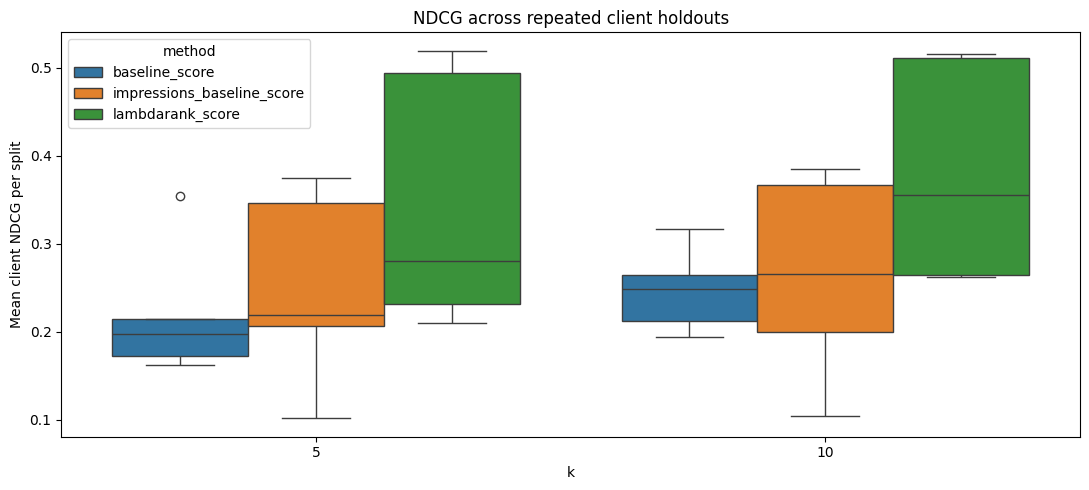

method,split_seed,k,baseline_score,impressions_baseline_score,lambdarank_score,lambdarank_minus_rule,lambdarank_minus_impressions
0,11,5,0.214330,0.207230,0.209959,-0.004371,0.002729
1,11,10,0.212344,0.199814,0.261800,0.049456,0.061986
2,23,5,0.162546,0.101752,0.232103,0.069556,0.130351
3,23,10,0.193604,0.104310,0.264826,0.071222,0.160516
4,42,5,0.197687,0.218794,0.280003,0.082316,0.061209
5,42,10,0.248911,0.265866,0.355012,0.106101,0.089147
6,61,5,0.354304,0.374671,0.519440,0.165136,0.144768
7,61,10,0.316873,0.384886,0.515385,0.198512,0.130499
8,97,5,0.172489,0.345930,0.494150,0.321662,0.148221
9,97,10,0.264465,0.366862,0.511671,0.247206,0.144808


In [15]:
metrics_summary = (
    metrics_detail.groupby(["method", "k"])["ndcg"]
    .agg(
        mean_ndcg="mean",
        std_ndcg="std",
        median_ndcg="median",
        p10_ndcg=lambda s: s.quantile(0.10),
        p90_ndcg=lambda s: s.quantile(0.90),
        clients_evaluated="count",
    )
    .reset_index()
    .sort_values(["k", "mean_ndcg"], ascending=[True, False])
)
display(metrics_summary)

split_summary = (
    metrics_detail.groupby(["split_seed", "method", "k"])["ndcg"]
    .mean().reset_index(name="mean_client_ndcg")
)
plt.figure(figsize=(11, 5))
sns.boxplot(data=split_summary, x="k", y="mean_client_ndcg", hue="method")
plt.title("NDCG across repeated client holdouts")
plt.ylabel("Mean client NDCG per split")
plt.tight_layout()
plt.show()

paired = split_summary.pivot_table(index=["split_seed", "k"], columns="method", values="mean_client_ndcg").reset_index()
if {"lambdarank_score", "baseline_score"}.issubset(paired.columns):
    paired["lambdarank_minus_rule"] = paired["lambdarank_score"] - paired["baseline_score"]
if {"lambdarank_score", "impressions_baseline_score"}.issubset(paired.columns):
    paired["lambdarank_minus_impressions"] = paired["lambdarank_score"] - paired["impressions_baseline_score"]
display(paired)


## 12. Build evidence-based recommendation eligibility

Ranking alone is not enough for a HIGH label. Recommendations must have reliable feature coverage, a minimum level of observed impressions, and evidence that the page had a meaningful negative trend in the historical feature windows. The rule uses **features only**, not target-window outcomes or relevance labels.

The target period is retained in the held-out queue for retrospective evaluation only; it must not be used as a live recommendation feature.

In [16]:
def add_recommendation_evidence(frame):
    out = frame.copy()
    out["recommendation_eligible"] = (
        (out["feat_active_days_60_90"] >= MIN_RECOMMENDATION_FEATURE_DAYS) &
        (out["feat_imp_60_90"] >= MIN_RECOMMENDATION_FEATURE_IMPRESSIONS) &
        out["feat_imp_log_ratio"].notna() &
        out["feat_pos_60_90"].notna()
    )
    out["historical_decline_evidence"] = out["feat_imp_log_ratio"] <= np.log(0.80)
    out["high_priority_evidence"] = (
        out["recommendation_eligible"] & out["historical_decline_evidence"]
    )
    return out

last_split_test = add_recommendation_evidence(last_split_test)
last_split_test["model_rank"] = last_split_test.groupby("client_hash_id")["lambdarank_score"].rank(method="first", ascending=False).astype(int)
last_split_test["baseline_rank"] = last_split_test.groupby("client_hash_id")["baseline_score"].rank(method="first", ascending=False).astype(int)
last_split_test["priority_tier"] = np.select(
    [
        last_split_test["recommendation_eligible"] &
        last_split_test["high_priority_evidence"] &
        (last_split_test["model_rank"] <= 5),
        last_split_test["recommendation_eligible"] &
        (last_split_test["model_rank"] <= 15),
        last_split_test["recommendation_eligible"],
    ],
    ["HIGH", "MEDIUM", "LOW"],
    default="NOT_ELIGIBLE",
)
display(last_split_test["priority_tier"].value_counts(dropna=False).to_frame("rows"))


,rows
priority_tier,
LOW,7835
NOT_ELIGIBLE,447
MEDIUM,75
HIGH,6


## 13. Join metadata and query signals into the recommendation queue

Metadata and query signals are joined after model prediction. Query fields can explain demand concentration or limited query visibility, but they remain context-only until their as-of date is verified. Left joins preserve recommendations without metadata.

In [17]:
queue = last_split_test.copy()
if not metadata_df.empty and "content_hash_id" in metadata_df.columns:
    queue = queue.merge(metadata_df, on="content_hash_id", how="left", validate="many_to_one")
if not qsignals_df.empty and "content_hash_id" in qsignals_df.columns:
    queue = queue.merge(qsignals_df, on="content_hash_id", how="left", validate="many_to_one")

def make_action(row):
    actions = []
    if not row.get("recommendation_eligible", False):
        return "Insufficient reliable historical evidence; monitor or validate data coverage before prioritizing."
    if row.get("historical_decline_evidence", False):
        actions.append("Investigate the historical impression decline; refresh only if content is outdated or incomplete")
    pos = row.get("feat_pos_60_90", np.nan)
    if pd.notna(pos) and 4 <= pos <= 20:
        actions.append("Review search intent, title/meta description, and missing subtopics")
    ctr = row.get("feat_ctr_60_90", np.nan)
    if pd.notna(ctr) and ctr < 0.02:
        actions.append("Review query-level CTR and snippet relevance before changing content")
    rare = row.get("rare_share", np.nan)
    if pd.notna(rare) and rare > 0.5:
        actions.append("Inspect long-tail query coverage and whether important subtopics are missing")
    return "; ".join(actions) if actions else "Review page and query evidence before deciding on a refresh"

queue["suggested_action"] = queue.apply(make_action, axis=1)
queue_cols = [
    "client_hash_id", "content_hash_id", "model_rank", "priority_tier",
    "recommendation_eligible", "high_priority_evidence", "historical_decline_evidence",
    "lambdarank_score", "baseline_rank", "baseline_score",
    "target_trend_pct", "target_imp_prev30", "target_imp_last30",
    "target_observed_days_prev30", "target_observed_days_last30",
    "feat_imp_60_90", "feat_imp_90_120", "feat_imp_log_ratio",
    "feat_active_days_60_90", "feat_pos_60_90", "feat_ctr_60_90",
    "suggested_action"
]
metadata_candidates = [
    "title", "content_title", "page_title", "meta_title",
    "url", "content_url", "canonical_url", "page_url",
    "published_at", "publish_date", "published_date", "created_at", "first_published_at"
]
query_candidates = [
    "visible_queries", "rare_share", "anon_share",
    "top_query_impressions", "kept_query_impressions", "top_query_share"
]
queue_cols += [c for c in metadata_candidates + query_candidates if c in queue.columns]
queue_cols = list(dict.fromkeys([c for c in queue_cols if c in queue.columns]))
display(queue.sort_values(["client_hash_id", "model_rank"]).groupby("client_hash_id", sort=False).head(5)[queue_cols].head(30))


,client_hash_id,content_hash_id,model_rank,priority_tier,recommendation_eligible,high_priority_evidence,historical_decline_evidence,lambdarank_score,baseline_rank,baseline_score,...,feat_active_days_60_90,feat_pos_60_90,feat_ctr_60_90,suggested_action,visible_queries,rare_share,anon_share,top_query_impressions,kept_query_impressions,top_query_share
3586,client_08a6a72ff48e62c0,content_b15bb01e85013477,1,MEDIUM,True,False,False,3.239380,1204,46.902101,...,30,7.848537,0.000000,"Review search intent, title/meta description, ...",50.0,0.058586,0.706510,512.0,2093.0,0.244625
3381,client_08a6a72ff48e62c0,content_a7296d5fc22a04ac,2,MEDIUM,True,False,False,3.185243,1630,44.444980,...,30,6.751213,0.000000,"Review search intent, title/meta description, ...",24.0,0.011270,0.736539,111.0,1007.0,0.110228
2924,client_08a6a72ff48e62c0,content_90ff4e763f53db71,3,MEDIUM,True,False,False,3.009784,1332,46.164964,...,30,7.340549,0.000000,"Review search intent, title/meta description, ...",14.0,0.037818,0.917177,68.0,382.0,0.178010
1191,client_08a6a72ff48e62c0,content_3ccf7b567d9deea3,4,MEDIUM,True,False,False,2.976977,1726,43.953556,...,30,5.963756,0.000000,"Review search intent, title/meta description, ...",17.0,0.069099,0.697425,155.0,544.0,0.284926
262,client_08a6a72ff48e62c0,content_0c82ab20843cc5f3,5,MEDIUM,True,False,False,2.792704,1455,45.439873,...,30,6.913973,0.000000,"Review search intent, title/meta description, ...",17.0,0.217178,0.691514,61.0,354.0,0.172316
5194,client_08d2847f24cf89c1,content_7c7f399ab41e3f41,1,MEDIUM,True,False,False,-1.121235,13,9.263333,...,23,44.469899,0.000000,Review query-level CTR and snippet relevance b...,7.0,0.277865,0.480377,64.0,154.0,0.415584
5196,client_08d2847f24cf89c1,content_842d54dbd6470483,2,MEDIUM,True,False,False,-1.596524,10,23.846154,...,25,10.531459,0.000000,"Review search intent, title/meta description, ...",1.0,0.047319,0.826498,40.0,40.0,1.000000
5192,client_08d2847f24cf89c1,content_60576ee1b4d36202,3,MEDIUM,True,False,False,-1.703496,11,22.788462,...,29,25.526047,0.003817,Review query-level CTR and snippet relevance b...,2.0,0.130935,0.768345,57.0,70.0,0.814286
5201,client_08d2847f24cf89c1,content_ff0212c6580d70db,4,NOT_ELIGIBLE,False,False,True,-1.826628,7,37.459190,...,21,10.088662,0.000000,Insufficient reliable historical evidence; mon...,3.0,0.027322,0.770492,48.0,74.0,0.648649
5193,client_08d2847f24cf89c1,content_6b26d9cd3949959d,5,MEDIUM,True,False,False,-1.983248,12,9.615385,...,28,30.515379,0.000000,Review query-level CTR and snippet relevance b...,5.0,0.247458,0.598305,30.0,91.0,0.329670


## 14. Inspect model/baseline disagreements and feature importance

,client_hash_id,content_hash_id,model_rank,baseline_rank,rank_shift_model_minus_baseline,relevance,target_trend_pct,lambdarank_score,baseline_score
70010,client_08a6a72ff48e62c0,content_759d035a810b245b,5110,91,5019,3,-0.646264,-2.992534,76.108466
69230,client_08a6a72ff48e62c0,content_134da73643e6fc29,4996,45,4951,2,-0.510000,-2.809622,82.250770
747,client_08a6a72ff48e62c0,content_e736d94ae0776853,4992,41,4951,3,-0.653846,-2.807051,82.432276
76234,client_08a6a72ff48e62c0,content_601f68964b8ebb6e,5020,73,4947,2,-0.429091,-2.835092,77.377327
70344,client_08a6a72ff48e62c0,content_aa2951f9f8a343e0,5108,170,4938,0,-0.134387,-2.988713,69.834247
71033,client_08a6a72ff48e62c0,content_583879e1e4843542,4939,19,4920,3,-0.627083,-2.747576,86.791771
26610,client_08a6a72ff48e62c0,content_28313fada49ec609,273,5162,-4889,0,-0.168003,-0.133712,1.495953
70552,client_08a6a72ff48e62c0,content_e7b9329f05d0868f,5151,265,4886,0,-0.170316,-3.117981,61.238633
69863,client_08a6a72ff48e62c0,content_8de8876c55492aae,4951,70,4881,0,-0.077922,-2.758318,77.751777
69754,client_08a6a72ff48e62c0,content_ec14d7f027c152f6,5134,256,4878,1,-0.317305,-3.061532,61.611237


,importance
feat_pos_volatility_60_90,1269
feat_imp_log_ratio,1163
log_feat_imp_60_90,1153
feat_pos_90_120,1105
feat_pos_60_90,1094
feat_position_change,975
log_feat_imp_90_120,940
feat_ctr_90_120,669
feat_ctr_60_90,586
feat_active_days_90_120,520


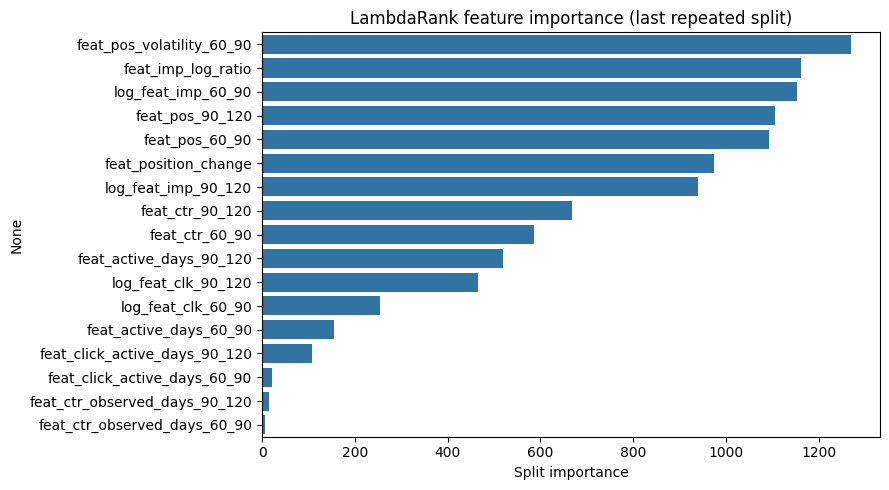

In [18]:
comparison = last_split_test.copy()
comparison["rank_shift_model_minus_baseline"] = comparison["model_rank"] - comparison["baseline_rank"]
display(comparison.reindex(comparison["rank_shift_model_minus_baseline"].abs().sort_values(ascending=False).index)[
    [c for c in ["client_hash_id", "content_hash_id", "model_rank", "baseline_rank",
                 "rank_shift_model_minus_baseline", "relevance", "target_trend_pct",
                 "lambdarank_score", "baseline_score"] if c in comparison.columns]
].head(30))

importance = last_split_importance
display(importance.to_frame())
plt.figure(figsize=(9, 5))
sns.barplot(x=importance.values, y=importance.index)
plt.title("LambdaRank feature importance (last repeated split)")
plt.xlabel("Split importance")
plt.tight_layout()
plt.show()


## 15. Train the final model and export artifacts

After repeated evaluation, fit a final model on all eligible rows, using the same training-only stratified cap policy if required. This model is for future scoring experiments; do not use it to report held-out evaluation metrics. The held-out queue below is from the final seed's test clients and remains out-of-client for that split.

In [19]:
final_frame_full = sort_group_frame(eligible)
final_frame, final_sampling_report = stratified_cap_training_groups(final_frame_full, seed=2026)
final_frame = sort_group_frame(final_frame)
final_imputer = SimpleImputer(strategy="median", keep_empty_features=True)
X_final = final_imputer.fit_transform(final_frame[feature_cols].replace([np.inf, -np.inf], np.nan))
y_final = final_frame["relevance"].to_numpy(dtype=int)
final_groups = group_sizes_for(final_frame)

final_ranker = LGBMRanker(
    objective="lambdarank",
    metric="ndcg",
    n_estimators=350,
    learning_rate=0.04,
    num_leaves=31,
    min_child_samples=25,
    subsample=0.85,
    colsample_bytree=0.85,
    reg_lambda=1.0,
    random_state=2026,
    n_jobs=-1,
    label_gain=[0, 1, 3, 7, 15],
    verbosity=-1,
)
final_ranker.fit(X_final, y_final, group=final_groups)

OUT_METRICS = "flyrank_stage2_1_ndcg_summary.csv"
OUT_DETAIL = "flyrank_stage2_1_ndcg_per_client_split.csv"
OUT_SPLITS = "flyrank_stage2_1_split_diagnostics.csv"
OUT_QUEUE = "flyrank_stage2_1_heldout_recommendation_queue.csv"
OUT_IMPORTANCE = "flyrank_stage2_1_feature_importance.csv"
OUT_COVERAGE = "flyrank_stage2_1_gsc_coverage_audit.csv"
OUT_CTR = "flyrank_stage2_1_ctr_missingness_audit.csv"
OUT_MODEL = "flyrank_stage2_1_lambdarank_model.joblib"

metrics_summary.to_csv(OUT_METRICS, index=False)
metrics_detail.to_csv(OUT_DETAIL, index=False)
split_report_df.to_csv(OUT_SPLITS, index=False)
queue.sort_values(["client_hash_id", "model_rank"])[queue_cols].to_csv(OUT_QUEUE, index=False)
importance.to_frame().to_csv(OUT_IMPORTANCE)
availability_audit.to_csv(OUT_COVERAGE, index=False)
ctr_audit.to_csv(OUT_CTR, index=False)

joblib.dump({
    "ranker": final_ranker,
    "imputer": final_imputer,
    "feature_cols": feature_cols,
    "label_definition": grade_names,
    "grouping": "client_hash_id",
    "feature_window": "days 60-120 before latest report date",
    "target_definition": "latest 30-day impression change versus preceding 30 days",
    "coverage_policy": {
        "min_target_observed_days_per_30d_window": MIN_TARGET_OBSERVED_DAYS,
        "min_feature_observed_days_per_30d_window": MIN_FEATURE_OBSERVED_DAYS,
        "min_previous_target_impressions": MIN_PREV_TARGET_IMPRESSIONS,
    },
    "recommendation_policy": {
        "min_feature_days": MIN_RECOMMENDATION_FEATURE_DAYS,
        "min_feature_impressions": MIN_RECOMMENDATION_FEATURE_IMPRESSIONS,
        "high_priority_requires_historical_decline_evidence": True,
    },
    "random_seeds": RANDOM_SEEDS,
    "query_signals_used_as_model_features": False,
    "warning": "Historical decline severity is a refresh-priority proxy, not causal refresh-uplift probability."
}, OUT_MODEL)

print("Saved artifacts:")
for filename in [OUT_METRICS, OUT_DETAIL, OUT_SPLITS, OUT_QUEUE, OUT_IMPORTANCE, OUT_COVERAGE, OUT_CTR, OUT_MODEL]:
    print(" -", filename)

try:
    from google.colab import files as colab_files
    for filename in [OUT_METRICS, OUT_DETAIL, OUT_SPLITS, OUT_QUEUE, OUT_IMPORTANCE, OUT_COVERAGE, OUT_CTR, OUT_MODEL]:
        colab_files.download(filename)
except Exception as exc:
    print("Automatic browser downloads unavailable; files remain in the Colab runtime:", exc)

# ---------------------------------------------------------------------------
# Final production-style inference: score ALL eligible candidates, not only
# the held-out clients used in the last evaluation split.
# ---------------------------------------------------------------------------
# The held-out queue has already been exported above for evaluation/inspection.
# It is deliberately not used as the final operational recommendation queue.

production_candidates = eligible.copy()
production_candidates = add_recommendation_evidence(production_candidates)
missing_prod_features = [c for c in feature_cols if c not in production_candidates.columns]
if missing_prod_features:
    raise ValueError(f"Production candidate frame is missing model features: {missing_prod_features}")

X_production = final_imputer.transform(
    production_candidates[feature_cols].replace([np.inf, -np.inf], np.nan)
)
production_candidates["lambdarank_score"] = final_ranker.predict(X_production)
production_candidates["baseline_score"] = pd.to_numeric(
    production_candidates.get("baseline_score", production_candidates.get("feat_imp_60_90", pd.Series(np.nan, index=production_candidates.index))),
    errors="coerce"
)
production_candidates["model_rank"] = production_candidates.groupby("client_hash_id")["lambdarank_score"].rank(
    method="first", ascending=False
).astype(int)
production_candidates["baseline_rank"] = production_candidates.groupby("client_hash_id")["baseline_score"].rank(
    method="first", ascending=False, na_option="bottom"
).astype(int)
production_candidates["priority_tier"] = np.select(
    [
        production_candidates["recommendation_eligible"]
        & production_candidates["high_priority_evidence"]
        & (production_candidates["model_rank"] <= 5),
        production_candidates["recommendation_eligible"]
        & (production_candidates["model_rank"] <= 15),
        production_candidates["recommendation_eligible"],
    ],
    ["HIGH", "MEDIUM", "LOW"],
    default="NOT_ELIGIBLE",
)

# Attach descriptive metadata after scoring. These fields are context only and
# are not fed to the model unless explicitly listed in feature_cols.
production_queue = production_candidates.copy()
if not metadata_df.empty and "content_hash_id" in metadata_df.columns:
    production_queue = production_queue.drop(
        columns=[c for c in metadata_df.columns if c != "content_hash_id" and c in production_queue.columns],
        errors="ignore",
    ).merge(metadata_df, on="content_hash_id", how="left", validate="many_to_one")
if not qsignals_df.empty and "content_hash_id" in qsignals_df.columns:
    production_queue = production_queue.drop(
        columns=[c for c in qsignals_df.columns if c != "content_hash_id" and c in production_queue.columns],
        errors="ignore",
    ).merge(qsignals_df, on="content_hash_id", how="left", validate="many_to_one")

# Reuse the human-readable action function defined in Section 13.
production_queue["suggested_action"] = production_queue.apply(make_action, axis=1)
production_queue["queue_scope"] = "all_eligible_candidates_scored_by_final_model"
production_queue["score_interpretation"] = "relative prioritization score; not probability of uplift"
queue = production_queue.copy()

production_queue_path = Path("outputs") / "stage2" / "flyrank_production_candidate_queue.csv"
production_queue_path.parent.mkdir(parents=True, exist_ok=True)
production_queue.sort_values(["client_hash_id", "model_rank"]).to_csv(production_queue_path, index=False)
print("Production-style queue saved:", production_queue_path)
print("All eligible candidate rows scored:", f"{len(production_queue):,}")
print("Clients represented:", f"{production_queue['client_hash_id'].nunique():,}")
print("Recommendation-eligible rows:", f"{int(production_queue['recommendation_eligible'].fillna(False).sum()):,}")
print("Held-out evaluation metrics remain in metrics_summary / metrics_detail and the evaluation exports above.")


Saved artifacts:
 - flyrank_stage2_1_ndcg_summary.csv
 - flyrank_stage2_1_ndcg_per_client_split.csv
 - flyrank_stage2_1_split_diagnostics.csv
 - flyrank_stage2_1_heldout_recommendation_queue.csv
 - flyrank_stage2_1_feature_importance.csv
 - flyrank_stage2_1_gsc_coverage_audit.csv
 - flyrank_stage2_1_ctr_missingness_audit.csv
 - flyrank_stage2_1_lambdarank_model.joblib


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

...

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRanker was fitted with feature names
  warnings.warn(


Production-style queue saved: outputs/stage2/flyrank_production_candidate_queue.csv
All eligible candidate rows scored: 78,900
Clients represented: 32
Recommendation-eligible rows: 76,474
Held-out evaluation metrics remain in metrics_summary / metrics_detail and the evaluation exports above.


## Stage 2.1 validation checklist and transition to Stage 3

Complete the GSC coverage, ranking evaluation, and recommendation-queue checks before using the queue operationally. Stage 3 below adds an intervention log and outcome measurement. Business impact cannot be estimated until actual recommendation decisions and refresh dates are recorded.

# Stage 3 — Measure recommendation adoption and post-refresh outcomes

## Objective

Move from *ranking content that appears at risk* to measuring whether the recommendations are used and what happens afterward.

This stage adds:
- a stable export of recommendation candidates;
- a human-editable intervention log;
- observed pre/post performance metrics with GSC availability checks;
- adoption and outcome summaries;
- a cautious comparison framework.

**Important:** a pre/post improvement is descriptive, not proof that a refresh caused the improvement. Seasonality, algorithm updates, demand changes, and other edits can affect traffic. Stronger causal estimates require a suitable comparison group or experiment.

In [20]:
from datetime import date
from pathlib import Path
import pandas as pd
import numpy as np

STAGE3_DIR = Path("outputs/stage3")
STAGE3_DIR.mkdir(parents=True, exist_ok=True)

# The queue is produced by Stage 2.1. Prefer the full final-model candidate queue if
# available; otherwise use the held-out queue for workflow testing only.
if "queue" in globals() and isinstance(queue, pd.DataFrame) and not queue.empty:
    stage3_candidates = queue.copy()
elif "last_split_test" in globals() and isinstance(last_split_test, pd.DataFrame):
    stage3_candidates = last_split_test.copy()
else:
    raise RuntimeError("Recommendation queue not found. Run the Stage 2.1 pipeline first.")

# Keep candidate export stable and avoid including the target label in an operational log.
candidate_cols = [
    c for c in [
        "client_hash_id", "content_hash_id", "model_rank", "priority_tier",
        "lambdarank_score", "baseline_rank", "baseline_score",
        "recommendation_eligible", "historical_decline_evidence",
        "feat_imp_60_90", "feat_imp_90_120", "feat_imp_log_ratio",
        "feat_pos_60_90", "feat_ctr_60_90", "data_end_date",
        "url", "canonical_url", "content_url", "page_url",
        "title", "content_title", "page_title", "meta_title"
    ] if c in stage3_candidates.columns
]
stage3_candidates = stage3_candidates[candidate_cols].copy()

if "data_end_date" in stage3_candidates.columns:
    stage3_candidates["recommendation_date"] = pd.to_datetime(
        stage3_candidates["data_end_date"], errors="coerce"
    ).dt.date
else:
    # This is a creation date for the workflow log, not a claim about when the
    # model was originally run. Replace it with the actual recommendation date.
    stage3_candidates["recommendation_date"] = pd.NaT

stage3_candidates["action_status"] = "not_reviewed"
stage3_candidates["refresh_date"] = pd.NaT
stage3_candidates["intervention_type"] = ""
stage3_candidates["owner"] = ""
stage3_candidates["notes"] = ""

candidate_path = STAGE3_DIR / "recommendation_candidates_stage3.csv"
stage3_candidates.to_csv(candidate_path, index=False)

# Human-editable intervention log. One row per recommendation decision/intervention.
intervention_columns = [
    "client_hash_id", "content_hash_id", "recommendation_date",
    "action_status", "refresh_date", "intervention_type", "owner", "notes"
]
intervention_path = STAGE3_DIR / "intervention_log_template.csv"
if not intervention_path.exists():
    stage3_candidates.reindex(columns=intervention_columns).to_csv(intervention_path, index=False)

print("Candidate export:", candidate_path)
print("Intervention log template:", intervention_path)
print("Candidate rows:", f"{len(stage3_candidates):,}")
print("Edit intervention_log_template.csv and fill actual review/action/refresh dates.")


Candidate export: outputs/stage3/recommendation_candidates_stage3.csv
Intervention log template: outputs/stage3/intervention_log_template.csv
Candidate rows: 78,900
Edit intervention_log_template.csv and fill actual review/action/refresh dates.


## 17. Define the intervention log

Use one row per client-content recommendation. Record whether it was reviewed, accepted, rejected, or deferred. For accepted recommendations, record the **actual refresh date** and type of change. Do not infer that a refresh occurred merely because a recommendation was generated.

Expected `action_status` values:
- `not_reviewed`
- `accepted`
- `rejected`
- `deferred`
- `refreshed`
- `no_change`

For outcome analysis, a valid `refresh_date` is required. A recommendation date is not a substitute for the actual refresh date.

In [21]:
# Load the intervention log. In Colab, upload/edit this CSV and point this path at it.
INTERVENTION_LOG_PATH = intervention_path

interventions = pd.read_csv(INTERVENTION_LOG_PATH)
required_log_cols = {
    "client_hash_id", "content_hash_id", "recommendation_date",
    "action_status", "refresh_date", "intervention_type"
}
missing_log_cols = sorted(required_log_cols - set(interventions.columns))
if missing_log_cols:
    raise ValueError(f"Intervention log is missing columns: {missing_log_cols}")

for col in ["recommendation_date", "refresh_date"]:
    interventions[col] = pd.to_datetime(interventions[col], errors="coerce")

interventions["action_status"] = (
    interventions["action_status"].fillna("not_reviewed").astype(str).str.strip().str.lower()
)

allowed_statuses = {
    "not_reviewed", "accepted", "rejected", "deferred", "refreshed", "no_change"
}
unknown_statuses = sorted(set(interventions["action_status"].dropna()) - allowed_statuses)
if unknown_statuses:
    raise ValueError(f"Unexpected action_status values: {unknown_statuses}")

duplicate_interventions = interventions.duplicated(
    ["client_hash_id", "content_hash_id", "recommendation_date"], keep=False
)
print("Intervention rows:", f"{len(interventions):,}")
print("Rows with duplicate recommendation keys:", f"{int(duplicate_interventions.sum()):,}")
display(interventions["action_status"].value_counts(dropna=False).to_frame("rows"))

if interventions["refresh_date"].notna().sum() == 0:
    print(
        "No actual refresh dates are recorded yet. Adoption metrics can be summarized, "
        "but post-refresh outcome metrics cannot be computed until the log is updated."
    )


Intervention rows: 78,900
Rows with duplicate recommendation keys: 0


,rows
action_status,
not_reviewed,78900


No actual refresh dates are recorded yet. Adoption metrics can be summarized, but post-refresh outcome metrics cannot be computed until the log is updated.


## 18. Measure pre/post GSC outcomes for recorded refreshes

For each recorded refresh, this query compares the 30 days before refresh with the 30 days after refresh. It includes only days where GSC was marked available and impressions were non-null. It reports observed days and refuses to call a comparison reliable unless each window meets a minimum coverage threshold.

This is a **descriptive outcome measure**, not a causal estimate. The post window must also be present in the warehouse; refreshes too close to the latest report date will have incomplete follow-up.

In [22]:

MIN_OUTCOME_OBSERVED_DAYS = 21

# Normalize in a copy; do not alter the source log unexpectedly.
interventions = interventions.copy()
interventions["action_status"] = (
    interventions["action_status"].fillna("").astype(str).str.strip().str.lower()
)
interventions["refresh_date"] = pd.to_datetime(
    interventions["refresh_date"], errors="coerce"
)

refresh_events = interventions.loc[
    interventions["action_status"].eq("refreshed")
    & interventions["refresh_date"].notna(),
    ["client_hash_id", "content_hash_id", "refresh_date"],
].drop_duplicates().copy()

outcome_columns = [
    "client_hash_id", "content_hash_id", "refresh_date",
    "pre_impressions_30d", "post_impressions_30d",
    "pre_observed_days", "post_observed_days",
    "pre_clicks_30d", "post_clicks_30d",
    "pre_avg_position", "post_avg_position",
    "impressions_change_pct", "clicks_change_pct",
    "coverage_sufficient", "outcome_status",
]


In [23]:

if refresh_events.empty:
    outcome_metrics = pd.DataFrame(columns=outcome_columns)
    print("No rows have action_status='refreshed' and a valid refresh_date.")
    print("This is expected until real refreshes have been completed and logged.")
else:
    refresh_events["refresh_date"] = refresh_events["refresh_date"].dt.date
    con.register("stage3_refresh_events", refresh_events)
    outcome_sql = f"""
    WITH events AS (
        SELECT client_hash_id, content_hash_id, CAST(refresh_date AS DATE) AS refresh_date
        FROM stage3_refresh_events
    ),
    daily AS (
        SELECT e.client_hash_id, e.content_hash_id, e.refresh_date, f.report_date,
            CASE WHEN f.gsc_data_available IS TRUE AND f.gsc_impressions IS NOT NULL
                 THEN f.gsc_impressions END AS valid_impressions,
            CASE WHEN f.gsc_data_available IS TRUE AND f.gsc_clicks IS NOT NULL
                 THEN f.gsc_clicks END AS valid_clicks,
            CASE WHEN f.gsc_data_available IS TRUE AND f.gsc_avg_position IS NOT NULL
                 THEN f.gsc_avg_position END AS valid_position
        FROM events e
        JOIN {TABLES["fact_daily"]} f
          ON f.client_hash_id = e.client_hash_id
         AND f.content_hash_id = e.content_hash_id
         AND f.report_date >= e.refresh_date - INTERVAL 30 DAY
         AND f.report_date < e.refresh_date + INTERVAL 30 DAY
    )
    SELECT client_hash_id, content_hash_id, refresh_date,
        SUM(valid_impressions) FILTER (
            WHERE report_date >= refresh_date - INTERVAL 30 DAY
              AND report_date < refresh_date
        ) AS pre_impressions_30d,
        SUM(valid_impressions) FILTER (
            WHERE report_date >= refresh_date
              AND report_date < refresh_date + INTERVAL 30 DAY
        ) AS post_impressions_30d,
        COUNT(valid_impressions) FILTER (
            WHERE report_date >= refresh_date - INTERVAL 30 DAY
              AND report_date < refresh_date
        ) AS pre_observed_days,
        COUNT(valid_impressions) FILTER (
            WHERE report_date >= refresh_date
              AND report_date < refresh_date + INTERVAL 30 DAY
        ) AS post_observed_days,
        SUM(valid_clicks) FILTER (
            WHERE report_date >= refresh_date - INTERVAL 30 DAY
              AND report_date < refresh_date
        ) AS pre_clicks_30d,
        SUM(valid_clicks) FILTER (
            WHERE report_date >= refresh_date
              AND report_date < refresh_date + INTERVAL 30 DAY
        ) AS post_clicks_30d,
        AVG(valid_position) FILTER (
            WHERE report_date >= refresh_date - INTERVAL 30 DAY
              AND report_date < refresh_date
        ) AS pre_avg_position,
        AVG(valid_position) FILTER (
            WHERE report_date >= refresh_date
              AND report_date < refresh_date + INTERVAL 30 DAY
        ) AS post_avg_position
    FROM daily
    GROUP BY 1, 2, 3
    """
    try:
        outcome_metrics = con.execute(outcome_sql).df()
    finally:
        con.unregister("stage3_refresh_events")

    outcome_metrics["coverage_sufficient"] = (
        (outcome_metrics["pre_observed_days"].fillna(0) >= MIN_OUTCOME_OBSERVED_DAYS)
        & (outcome_metrics["post_observed_days"].fillna(0) >= MIN_OUTCOME_OBSERVED_DAYS)
    )

    def _safe_pct_change(post, pre):
        post = pd.to_numeric(post, errors="coerce")
        pre = pd.to_numeric(pre, errors="coerce")
        result = pd.Series(np.nan, index=post.index, dtype=float)
        valid = pre.notna() & post.notna() & (pre > 0)
        result.loc[valid] = (post.loc[valid] - pre.loc[valid]) / pre.loc[valid] * 100
        return result

    outcome_metrics["impressions_change_pct"] = _safe_pct_change(
        outcome_metrics["post_impressions_30d"], outcome_metrics["pre_impressions_30d"]
    )
    outcome_metrics["clicks_change_pct"] = _safe_pct_change(
        outcome_metrics["post_clicks_30d"], outcome_metrics["pre_clicks_30d"]
    )
    outcome_metrics["outcome_status"] = np.where(
        outcome_metrics["coverage_sufficient"], "sufficient_coverage", "insufficient_coverage"
    )

display(outcome_metrics.head(20))
outcome_path = STAGE3_DIR / "refresh_outcomes_pre_post.csv"
outcome_metrics.to_csv(outcome_path, index=False)
print("Outcome export:", outcome_path)


No rows have action_status='refreshed' and a valid refresh_date.
This is expected until real refreshes have been completed and logged.


,client_hash_id,content_hash_id,refresh_date,pre_impressions_30d,post_impressions_30d,pre_observed_days,post_observed_days,pre_clicks_30d,post_clicks_30d,pre_avg_position,post_avg_position,impressions_change_pct,clicks_change_pct,coverage_sufficient,outcome_status


Outcome export: outputs/stage3/refresh_outcomes_pre_post.csv


## 19. Summarize recommendation adoption and observed outcomes

The first summary measures operational adoption. The second summarizes pre/post performance only for refreshes with sufficient data coverage. Treat these as monitoring metrics, not causal impact estimates.

In [24]:

status_summary = (
    interventions["action_status"].replace("", "missing_status")
    .value_counts(dropna=False).rename_axis("action_status").reset_index(name="recommendations")
)
total_logged = int(len(interventions))
status_summary["share_of_logged_recommendations_pct"] = (
    status_summary["recommendations"] / total_logged * 100 if total_logged else np.nan
)
display(status_summary)

if outcome_metrics.empty:
    print("No completed refresh outcomes are available yet; the pre/post summary is skipped.")
else:
    covered = outcome_metrics.loc[outcome_metrics["coverage_sufficient"]].copy()
    print(f"Refreshes with sufficient pre/post coverage: {len(covered):,} / {len(outcome_metrics):,}")
    if covered.empty:
        print("Refreshes exist, but none meet the observed-day coverage threshold.")
    else:
        display(covered[[
            "impressions_change_pct", "clicks_change_pct",
            "pre_avg_position", "post_avg_position"
        ]].describe(percentiles=[.1, .25, .5, .75, .9]).T)
        print("These are observed pre/post changes, not causal impact estimates.")


,action_status,recommendations,share_of_logged_recommendations_pct
0,not_reviewed,78900,100.0


No completed refresh outcomes are available yet; the pre/post summary is skipped.


## 20. Matched comparison: refreshed pages vs. similar non-refreshed pages

This section builds a descriptive matched comparison using the intervention log. For each refreshed page, it selects non-refreshed pages from the same client, aligns their pre/post windows to the treated page's refresh date, and matches on pre-period impressions, clicks, and average position. The outcome is change in log1p(impressions) to reduce skew.
Important limitations:
- Controls must be genuinely not refreshed during the event window; incomplete intervention logs can misclassify controls.
- Matching on observed covariates does not eliminate unmeasured confounding.
- This is exploratory observational analysis, not proof of causal impact.
- Run only after the intervention log contains real refresh dates and the 30-day post window is present in the warehouse.

## 21. Validate intervention records and set analysis parameters
Each treatment event must have action_status='refreshed' and a real refresh_date. We exclude events without enough time for the full post-period. We also require enough GSC-observed days in both windows. Adjust the thresholds only after reviewing coverage.

In [25]:

from pathlib import Path
import numpy as np
import pandas as pd

STAGE3_DIR = Path("outputs/stage3")
STAGE3_DIR.mkdir(parents=True, exist_ok=True)

PRE_DAYS = 30
POST_DAYS = 30
MIN_DAYS_PER_WINDOW = 21
N_CONTROLS_PER_TREATMENT = 3

if "interventions" not in globals() or not isinstance(interventions, pd.DataFrame):
    log_path = STAGE3_DIR / "intervention_log_template.csv"
    if not log_path.exists():
        raise FileNotFoundError(
            f"Intervention log not found at {log_path}. Run the Stage 3 export cell first."
        )
    interventions = pd.read_csv(log_path)

required = {"client_hash_id", "content_hash_id", "action_status", "refresh_date"}
missing = required - set(interventions.columns)
if missing:
    raise ValueError(f"interventions is missing required columns: {sorted(missing)}")

events_all = interventions.copy()
events_all["action_status"] = (
    events_all["action_status"].fillna("").astype(str).str.strip().str.lower()
)
events_all["refresh_date"] = pd.to_datetime(events_all["refresh_date"], errors="coerce")

print("Intervention-log rows:", f"{len(events_all):,}")
display(events_all["action_status"].value_counts(dropna=False).to_frame("rows"))
display(
    events_all.assign(has_valid_refresh_date=events_all["refresh_date"].notna())
    .groupby(["action_status", "has_valid_refresh_date"], dropna=False)
    .size().rename("rows").reset_index()
)

events = events_all.loc[
    events_all["action_status"].eq("refreshed") & events_all["refresh_date"].notna(),
    ["client_hash_id", "content_hash_id", "refresh_date"],
].drop_duplicates().copy()

# Prevent events with an incomplete 30-day post window from entering impact analysis.
# max_report_date is defined by the earlier schema/date-coverage section in this notebook.
if "max_report_date" in globals() and pd.notna(max_report_date):
    max_report_ts = pd.to_datetime(max_report_date)
    complete_post_cutoff = max_report_ts.normalize() - pd.Timedelta(days=POST_DAYS - 1)
    events = events.loc[events["refresh_date"].dt.normalize() <= complete_post_cutoff].copy()

if events.empty:
    print(
        "No qualifying completed refresh events with valid dates and a complete post window. "
        "Sections 22–24 will safely skip comparison analysis."
    )
    events = pd.DataFrame(columns=[
        "client_hash_id", "content_hash_id", "refresh_date", "event_id"
    ])
    SKIP_STAGE3_DID = True
else:
    events["refresh_date"] = events["refresh_date"].dt.date
    events = events.reset_index(drop=True)
    events["event_id"] = np.arange(len(events), dtype=int)
    SKIP_STAGE3_DID = False
    print(f"Qualifying refresh events: {len(events):,}")

# Always register a table with a predictable schema, including the empty case.
if "stage3_treatment_events" in getattr(con, "list_tables", lambda: [])():
    con.unregister("stage3_treatment_events")
con.register("stage3_treatment_events", events)
print(f"Using {PRE_DAYS}-day pre and {POST_DAYS}-day post windows; "
      f"minimum {MIN_DAYS_PER_WINDOW} observed impression days per window.")


Intervention-log rows: 78,900


,rows
action_status,
not_reviewed,78900


,action_status,has_valid_refresh_date,rows
0,not_reviewed,False,78900


No qualifying completed refresh events with valid dates and a complete post window. Sections 22–24 will safely skip comparison analysis.
Using 30-day pre and 30-day post windows; minimum 21 observed impression days per window.


## 22. Match controls using pre-refresh characteristics
The query aggregates only observed GSC metrics. Potential controls are pages from the same client that are not the treated page and do not have a logged refresh within the event's pre/post window. Control pages are matched later using pre-period impressions, clicks, and average position.

In [26]:

# Uses MIN_DAYS_PER_WINDOW defined in Section 21.
if SKIP_STAGE3_DID or events.empty:
    comparison_pages = pd.DataFrame()
    print("Skipped Section 22: no qualifying real refresh events.")
else:
    comparison_sql = f"""
    WITH events AS (
        SELECT event_id, client_hash_id, content_hash_id AS treated_content_hash_id,
               CAST(refresh_date AS DATE) AS refresh_date
        FROM stage3_treatment_events
    ),
    event_pages AS (
        SELECT e.event_id, e.client_hash_id, e.treated_content_hash_id,
               e.treated_content_hash_id AS content_hash_id, e.refresh_date,
               TRUE AS is_treated
        FROM events e
        UNION ALL
        SELECT e.event_id, e.client_hash_id, e.treated_content_hash_id,
               f.content_hash_id, e.refresh_date, FALSE AS is_treated
        FROM events e
        JOIN {TABLES["fact_daily"]} f
          ON f.client_hash_id = e.client_hash_id
         AND f.report_date >= e.refresh_date - INTERVAL {PRE_DAYS} DAY
         AND f.report_date < e.refresh_date + INTERVAL {POST_DAYS} DAY
         AND f.content_hash_id <> e.treated_content_hash_id
        GROUP BY e.event_id, e.client_hash_id, e.treated_content_hash_id,
                 f.content_hash_id, e.refresh_date
    ),
    candidate_pages AS (SELECT DISTINCT * FROM event_pages),
    eligible_pages AS (
        SELECT p.*
        FROM candidate_pages p
        WHERE p.is_treated
           OR NOT EXISTS (
               SELECT 1 FROM stage3_treatment_events other
               WHERE other.client_hash_id = p.client_hash_id
                 AND other.content_hash_id = p.content_hash_id
                 AND CAST(other.refresh_date AS DATE) >= p.refresh_date - INTERVAL {PRE_DAYS} DAY
                 AND CAST(other.refresh_date AS DATE) < p.refresh_date + INTERVAL {POST_DAYS} DAY
           )
    ),
    daily AS (
        SELECT p.event_id, p.client_hash_id, p.treated_content_hash_id,
               p.content_hash_id, p.refresh_date, p.is_treated, f.report_date,
               CASE WHEN f.gsc_data_available IS TRUE AND f.gsc_impressions IS NOT NULL
                    THEN f.gsc_impressions END AS impressions,
               CASE WHEN f.gsc_data_available IS TRUE AND f.gsc_clicks IS NOT NULL
                    THEN f.gsc_clicks END AS clicks,
               CASE WHEN f.gsc_data_available IS TRUE AND f.gsc_avg_position IS NOT NULL
                    THEN f.gsc_avg_position END AS avg_position
        FROM eligible_pages p
        JOIN {TABLES["fact_daily"]} f
          ON f.client_hash_id = p.client_hash_id
         AND f.content_hash_id = p.content_hash_id
         AND f.report_date >= p.refresh_date - INTERVAL {PRE_DAYS} DAY
         AND f.report_date < p.refresh_date + INTERVAL {POST_DAYS} DAY
    ),
    aggregated AS (
        SELECT event_id, client_hash_id, treated_content_hash_id, content_hash_id,
               refresh_date, is_treated,
               SUM(impressions) FILTER (
                   WHERE report_date >= refresh_date - INTERVAL {PRE_DAYS} DAY
                     AND report_date < refresh_date
               ) AS pre_impressions,
               SUM(impressions) FILTER (
                   WHERE report_date >= refresh_date
                     AND report_date < refresh_date + INTERVAL {POST_DAYS} DAY
               ) AS post_impressions,
               COUNT(impressions) FILTER (
                   WHERE report_date >= refresh_date - INTERVAL {PRE_DAYS} DAY
                     AND report_date < refresh_date
               ) AS pre_impression_days,
               COUNT(impressions) FILTER (
                   WHERE report_date >= refresh_date
                     AND report_date < refresh_date + INTERVAL {POST_DAYS} DAY
               ) AS post_impression_days,
               SUM(clicks) FILTER (
                   WHERE report_date >= refresh_date - INTERVAL {PRE_DAYS} DAY
                     AND report_date < refresh_date
               ) AS pre_clicks,
               SUM(clicks) FILTER (
                   WHERE report_date >= refresh_date
                     AND report_date < refresh_date + INTERVAL {POST_DAYS} DAY
               ) AS post_clicks,
               AVG(avg_position) FILTER (
                   WHERE report_date >= refresh_date - INTERVAL {PRE_DAYS} DAY
                     AND report_date < refresh_date
               ) AS pre_avg_position,
               AVG(avg_position) FILTER (
                   WHERE report_date >= refresh_date
                     AND report_date < refresh_date + INTERVAL {POST_DAYS} DAY
               ) AS post_avg_position
        FROM daily
        GROUP BY 1,2,3,4,5,6
    )
    SELECT *,
        CASE WHEN pre_impressions IS NOT NULL AND post_impressions IS NOT NULL
             THEN LN(1 + post_impressions) - LN(1 + pre_impressions) END
             AS log_impression_change,
        CASE WHEN pre_clicks IS NOT NULL AND post_clicks IS NOT NULL
             THEN LN(1 + post_clicks) - LN(1 + pre_clicks) END
             AS log_click_change,
        (pre_impression_days >= {MIN_DAYS_PER_WINDOW}
         AND post_impression_days >= {MIN_DAYS_PER_WINDOW}) AS sufficient_coverage
    FROM aggregated
    """
    comparison_pages = con.execute(comparison_sql).df()
    print("Treatment/control page-event rows:", f"{len(comparison_pages):,}")
    if comparison_pages.empty:
        print("The query returned no page-events. Check GSC coverage and event IDs.")
    else:
        display(comparison_pages.head())


Skipped Section 22: no qualifying real refresh events.


## 23. Match controls using pre-refresh characteristics
For each treatment event, select up to three same-client control pages with sufficient pre/post coverage and the closest pre-period impressions and average position. Matching is done on pre-refresh information only. This is a transparent nearest-neighbour heuristic, not a randomized design.

In [27]:

if SKIP_STAGE3_DID or comparison_pages.empty:
    matched_pages = pd.DataFrame()
    print("Skipped matching: no qualifying treatment events or candidate page-events.")
else:
    pages = comparison_pages.copy()
    for col in [
        "pre_impressions", "pre_clicks", "pre_avg_position",
        "post_impressions", "post_clicks", "log_impression_change"
    ]:
        pages[col] = pd.to_numeric(pages[col], errors="coerce")
    pages["sufficient_coverage"] = pages["sufficient_coverage"].fillna(False).astype(bool)

    # Matching requires observed pre-impressions and average position. A zero impression
    # value is allowed; missing data is not silently converted to zero.
    pages["match_log_pre_impressions"] = np.log1p(pages["pre_impressions"].clip(lower=0))
    pages["match_log_pre_clicks"] = np.log1p(pages["pre_clicks"].clip(lower=0))

    def robust_scale(series):
        series = pd.to_numeric(series, errors="coerce")
        med = series.median()
        iqr = series.quantile(.75) - series.quantile(.25)
        if pd.isna(iqr) or iqr == 0:
            iqr = series.std()
        if pd.isna(iqr) or iqr == 0:
            iqr = 1.0
        return (series - med) / iqr

    pages["z_pre_impressions"] = robust_scale(pages["match_log_pre_impressions"])
    pages["z_pre_clicks"] = robust_scale(pages["match_log_pre_clicks"])
    pages["z_pre_position"] = robust_scale(pages["pre_avg_position"])

    treated = pages.loc[pages["is_treated"].eq(True) & pages["sufficient_coverage"]].copy()
    controls = pages.loc[pages["is_treated"].eq(False) & pages["sufficient_coverage"]].copy()

    matched_rows = []
    for _, tr in treated.iterrows():
        if pd.isna(tr["z_pre_impressions"]) or pd.isna(tr["z_pre_position"]):
            continue
        pool = controls.loc[
            controls["event_id"].eq(tr["event_id"])
            & controls["client_hash_id"].eq(tr["client_hash_id"])
            & controls["pre_impressions"].notna()
            & controls["pre_avg_position"].notna()
        ].copy()
        if pool.empty:
            continue
        pool["match_distance"] = np.sqrt(
            (pool["z_pre_impressions"] - tr["z_pre_impressions"]) ** 2
            + (pool["z_pre_clicks"] - tr["z_pre_clicks"]) ** 2
            + (pool["z_pre_position"] - tr["z_pre_position"]) ** 2
        )
        pool = pool.replace([np.inf, -np.inf], np.nan).dropna(subset=["match_distance"])
        pool = pool.sort_values("match_distance").head(N_CONTROLS_PER_TREATMENT)
        if pool.empty:
            continue

        tr_row = tr.to_dict()
        tr_row["matched_role"] = "treated"
        tr_row["matched_control_content_hash_id"] = None
        tr_row["match_distance"] = 0.0
        matched_rows.append(tr_row)
        for _, ctrl in pool.iterrows():
            row = ctrl.to_dict()
            row["matched_role"] = "control"
            row["matched_control_content_hash_id"] = row["content_hash_id"]
            matched_rows.append(row)

    matched_pages = pd.DataFrame(matched_rows)
    matched_path = STAGE3_DIR / "matched_treatment_controls.csv"
    matched_pages.to_csv(matched_path, index=False)
    if matched_pages.empty:
        print("No treatment events had sufficient coverage and eligible same-client controls.")
    else:
        print("Matched page-event rows:", f"{len(matched_pages):,}")
        display(matched_pages[[
            "event_id", "client_hash_id", "treated_content_hash_id",
            "content_hash_id", "matched_role", "match_distance",
            "pre_impressions", "pre_avg_position", "pre_impression_days",
            "post_impression_days"
        ]].head(20))
    print("Matched-pairs export:", matched_path)


Skipped matching: no qualifying treatment events or candidate page-events.


## 24. Estimate descriptive Difference-in-Differences
The outcome is the change in log(1 + 30-day impressions) from pre to post. For each event, the treated page's change is compared with the mean change among its matched controls. Positive DiD means the treated page improved more (or declined less) than its controls on this log scale.
This is not automatically causal: the design assumes comparable trends and no important unmeasured differences. Use it as a preliminary observational estimate and inspect sample size and pre-treatment trends before making business claims.

In [28]:
did_event_results = pd.DataFrame()
did_summary = pd.DataFrame()

if matched_pages.empty:
    print("No matched sample; DiD cannot be estimated. No fabricated estimate was created.")
else:
    valid = matched_pages.loc[
        matched_pages["sufficient_coverage"].fillna(False)
        & matched_pages["log_impression_change"].notna()
    ].copy()

    group_keys = ["event_id", "client_hash_id", "treated_content_hash_id", "refresh_date"]
    treated_change = (
        valid.loc[valid["matched_role"].eq("treated")]
        .groupby(group_keys)["log_impression_change"].mean()
        .rename("treated_log_change")
    )
    control_change = (
        valid.loc[valid["matched_role"].eq("control")]
        .groupby(group_keys)["log_impression_change"].mean()
        .rename("control_mean_log_change")
    )

    did_event_results = pd.concat([treated_change, control_change], axis=1).reset_index()
    # A DiD is estimable only if both sides exist for the same event.
    did_event_results = did_event_results.dropna(
        subset=["treated_log_change", "control_mean_log_change"]
    ).copy()
    did_event_results["did_log_impressions"] = (
        did_event_results["treated_log_change"] - did_event_results["control_mean_log_change"]
    )
    did_event_results["approx_relative_lift_pct"] = (
        np.exp(did_event_results["did_log_impressions"]) - 1
    ) * 100

    event_path = STAGE3_DIR / "difference_in_differences_by_event.csv"
    did_event_results.to_csv(event_path, index=False)

    if did_event_results.empty:
        print("No events had both valid treated and matched-control outcome changes; DiD skipped.")
    else:
        did_summary = did_event_results[
            ["did_log_impressions", "approx_relative_lift_pct"]
        ].describe()
        display(did_summary)


No matched sample; DiD cannot be estimated. No fabricated estimate was created.


## 25. Interpretation and limitations

- **Observational, Not Causal:** The pre/post metrics and Difference-in-Differences (DiD) comparisons report *observed* traffic changes, but they do not definitively prove the content refresh *caused* the uplift. External factors like seasonality, Google core algorithm updates, and macro demand shifts are not fully isolated.
- **Unmeasured Confounding:** The control matching process pairs pages based on historical impressions, clicks, and ranking positions. It cannot account for unmeasured variables such as new backlinks, changes in search intent, or overall site authority shifts.
- **Strict Data Dependencies:** Impact measurement strictly relies on accurate, manual intervention logging. Without recording an actual `refresh_date` and having sufficient GSC coverage in the post-period, outcomes cannot be validated.
- **Model Scope:** The LambdaRank model identifies pages with severe historical declines and ranks them by recovery opportunity. It is a prioritization tool, not a guarantee that a refresh will yield positive results.
- **Next Steps for Rigor:** To estimate true causal impact, consider adopting a randomized holdout experiment where eligible recommendations are randomly assigned to either a "refresh" (treatment) or "do not refresh" (control) group over a defined testing window.

# Stage 4 — Production readiness, versioned releases, and monitoring

This section validates the final production-style queue and writes versioned artifacts. A passing checklist is a minimum technical release gate, not evidence of causal impact or proof that the system is ready for unattended deployment.


## 26. Define the Stage 4 release contract

Each run should produce:
- a versioned model bundle and a manifest describing its features and training/evaluation context;
- a dated recommendation snapshot with a stable schema;
- data-quality and recommendation-volume reports;
- a feature-distribution reference for future drift comparisons;
- a release checklist that records whether basic gates passed.

Do not silently replace prior dated snapshots. The `latest` files are convenience copies; dated files are the audit trail.


In [29]:
from pathlib import Path
from datetime import datetime, timezone
import json, hashlib, joblib
import numpy as np
import pandas as pd

STAGE4_DIR = Path("outputs/stage4")
MODEL_DIR = STAGE4_DIR / "models"
SNAPSHOT_DIR = STAGE4_DIR / "snapshots"
MONITOR_DIR = STAGE4_DIR / "monitoring"
for _p in [STAGE4_DIR, MODEL_DIR, SNAPSHOT_DIR, MONITOR_DIR]:
    _p.mkdir(parents=True, exist_ok=True)

RUN_TS = datetime.now(timezone.utc)
RUN_ID = RUN_TS.strftime("%Y%m%dT%H%M%SZ")
RUN_DATE = RUN_TS.date().isoformat()
print("Stage 4 run:", RUN_ID)
print("Output directory:", STAGE4_DIR.resolve())


Stage 4 run: 20261015T215222Z
Output directory: /content/flyrank-ml-internship-starter/outputs/stage4


## 27. Validate required runtime objects and schemas

This cell checks that the ranking pipeline created the expected model, imputer, feature list, eligible data, and recommendation queue. It fails early with a readable message rather than producing incomplete release files.


In [30]:
required_objects = ["final_ranker", "final_imputer", "feature_cols", "eligible", "queue"]
missing_objects = [name for name in required_objects if name not in globals()]
if missing_objects:
    raise RuntimeError(
        "Stage 4 prerequisites are missing: " + ", ".join(missing_objects) +
        ". Run the Stage 2 model-training/export cells first."
    )

if not isinstance(eligible, pd.DataFrame) or eligible.empty:
    raise ValueError("`eligible` must be a non-empty pandas DataFrame.")
if not isinstance(queue, pd.DataFrame) or queue.empty:
    raise ValueError("`queue` must be a non-empty recommendation DataFrame.")
if not feature_cols:
    raise ValueError("`feature_cols` is empty.")
missing_features = [c for c in feature_cols if c not in eligible.columns]
if missing_features:
    raise ValueError(f"Training/evaluation frame is missing model features: {missing_features}")

required_queue_keys = ["client_hash_id", "content_hash_id"]
missing_queue_keys = [c for c in required_queue_keys if c not in queue.columns]
if missing_queue_keys:
    raise ValueError(f"Recommendation queue is missing keys: {missing_queue_keys}")

print(f"Eligible rows: {len(eligible):,}")
print(f"Eligible clients: {eligible['client_hash_id'].nunique():,}" if "client_hash_id" in eligible else "Eligible client count unavailable")
print(f"Queue rows: {len(queue):,}")
print(f"Model features: {len(feature_cols)}")


Eligible rows: 78,900
Eligible clients: 32
Queue rows: 78,900
Model features: 17


## 28. Create a stable production recommendation snapshot

The queue now comes from the final fitted ranker scoring every row in the eligible candidate frame, rather than the final held-out split. Evaluation metrics remain separate. The snapshot excludes target labels where possible, keeps operational evidence and metadata, and includes run identifiers for traceability.


In [31]:
# Prefer operationally useful columns while allowing schema-aware exports.
preferred_queue_cols = [
    "client_hash_id", "content_hash_id", "model_rank", "priority_tier",
    "lambdarank_score", "baseline_rank", "baseline_score",
    "recommendation_eligible", "historical_decline_evidence",
    "feat_imp_60_90", "feat_imp_90_120", "feat_imp_log_ratio",
    "feat_pos_60_90", "feat_ctr_60_90", "data_end_date",
    "url", "canonical_url", "content_url", "page_url",
    "title", "content_title", "page_title", "meta_title"
]
snapshot_cols = [c for c in preferred_queue_cols if c in queue.columns]
stage4_snapshot = queue.loc[:, snapshot_cols].copy()

# Use stable sort keys that exist in the queue.
sort_cols = [c for c in ["client_hash_id", "model_rank", "lambdarank_score", "content_hash_id"] if c in stage4_snapshot.columns]
ascending = [False if c in {"lambdarank_score"} else True for c in sort_cols]
if sort_cols:
    stage4_snapshot = stage4_snapshot.sort_values(sort_cols, ascending=ascending, na_position="last")

stage4_snapshot.insert(0, "run_id", RUN_ID)
stage4_snapshot.insert(1, "run_date_utc", RUN_DATE)

dated_snapshot_path = SNAPSHOT_DIR / f"recommendation_queue_{RUN_ID}.csv"
latest_snapshot_path = STAGE4_DIR / "recommendation_queue_latest.csv"
stage4_snapshot.to_csv(dated_snapshot_path, index=False)
stage4_snapshot.to_csv(latest_snapshot_path, index=False)

print("Dated recommendation snapshot:", dated_snapshot_path)
print("Latest convenience snapshot:", latest_snapshot_path)
print("Snapshot rows:", f"{len(stage4_snapshot):,}")
print("Exported columns:", snapshot_cols)


Dated recommendation snapshot: outputs/stage4/snapshots/recommendation_queue_20261015T215222Z.csv
Latest convenience snapshot: outputs/stage4/recommendation_queue_latest.csv
Snapshot rows: 78,900
Exported columns: ['client_hash_id', 'content_hash_id', 'model_rank', 'priority_tier', 'lambdarank_score', 'baseline_rank', 'baseline_score', 'recommendation_eligible', 'historical_decline_evidence', 'feat_imp_60_90', 'feat_imp_90_120', 'feat_imp_log_ratio', 'feat_pos_60_90', 'feat_ctr_60_90', 'data_end_date']


## 29. Build data-quality and recommendation-volume reports

The checks summarize missing/non-finite model inputs, duplicate recommendation keys, queue priority distribution, and queue eligibility. These are release diagnostics—not automatic proof that the data is correct. Review unusual counts before using a queue operationally.


In [32]:
# Feature-level quality report on the eligible modeling frame.
quality_rows = []
for col in feature_cols:
    s = pd.to_numeric(eligible[col], errors="coerce")
    quality_rows.append({
        "feature": col,
        "rows": int(len(s)),
        "missing_or_non_numeric_pct": float(s.isna().mean() * 100) if len(s) else np.nan,
        "infinite_pct": float(np.isinf(s.to_numpy(dtype=float, na_value=np.nan)).mean() * 100) if len(s) else np.nan,
        "unique_values": int(s.nunique(dropna=True)),
    })
feature_quality_report = pd.DataFrame(quality_rows)
feature_quality_path = MONITOR_DIR / f"feature_quality_{RUN_ID}.csv"
feature_quality_report.to_csv(feature_quality_path, index=False)

queue_key_duplicates = int(stage4_snapshot.duplicated(["client_hash_id", "content_hash_id"]).sum())
queue_volume = pd.DataFrame([{
    "run_id": RUN_ID,
    "run_date_utc": RUN_DATE,
    "queue_rows": int(len(stage4_snapshot)),
    "unique_clients": int(stage4_snapshot["client_hash_id"].nunique()),
    "unique_content_items": int(stage4_snapshot["content_hash_id"].nunique()),
    "duplicate_client_content_keys": queue_key_duplicates,
    "eligible_true_rows": int(stage4_snapshot["recommendation_eligible"].fillna(False).astype(bool).sum()) if "recommendation_eligible" in stage4_snapshot else None,
}])
if "priority_tier" in stage4_snapshot:
    tier_counts = (stage4_snapshot["priority_tier"].fillna("UNKNOWN").astype(str)
                   .value_counts(dropna=False).rename_axis("priority_tier").reset_index(name="rows"))
else:
    tier_counts = pd.DataFrame(columns=["priority_tier", "rows"])

queue_volume_path = MONITOR_DIR / f"queue_volume_{RUN_ID}.csv"
tier_counts_path = MONITOR_DIR / f"priority_tier_counts_{RUN_ID}.csv"
queue_volume.to_csv(queue_volume_path, index=False)
tier_counts.to_csv(tier_counts_path, index=False)

display(feature_quality_report.sort_values("missing_or_non_numeric_pct", ascending=False).head(20))
display(queue_volume)
display(tier_counts)
print("Feature quality report:", feature_quality_path)


,feature,rows,missing_or_non_numeric_pct,infinite_pct,unique_values
0,log_feat_imp_60_90,78900,0.0,0.0,16108
1,log_feat_imp_90_120,78900,0.0,0.0,23498
2,log_feat_clk_60_90,78900,0.0,0.0,515
3,log_feat_clk_90_120,78900,0.0,0.0,1006
4,feat_ctr_60_90,78900,0.0,0.0,25063
5,feat_ctr_90_120,78900,0.0,0.0,27663
6,feat_imp_log_ratio,78900,0.0,0.0,77039
7,feat_pos_60_90,78900,0.0,0.0,78578
8,feat_pos_90_120,78900,0.0,0.0,78578
9,feat_position_change,78900,0.0,0.0,78580


,run_id,run_date_utc,queue_rows,unique_clients,unique_content_items,duplicate_client_content_keys,eligible_true_rows
0,20261015T215222Z,2026-10-15,78900,32,78900,0,76474


,priority_tier,rows
0,LOW,76057
1,NOT_ELIGIBLE,2426
2,MEDIUM,385
3,HIGH,32


Feature quality report: outputs/stage4/monitoring/feature_quality_20261015T215222Z.csv


## 30. Save a feature-drift reference

The reference stores feature quantiles and summary statistics from the eligible frame available in this run. In future runs, compare the same features and definitions against this reference. A changed distribution is a signal to investigate, not automatically a reason to retrain.


In [33]:
drift_rows = []
for col in feature_cols:
    s = pd.to_numeric(eligible[col], errors="coerce").replace([np.inf, -np.inf], np.nan).dropna()
    drift_rows.append({
        "run_id": RUN_ID,
        "feature": col,
        "n_non_null": int(s.shape[0]),
        "mean": float(s.mean()) if len(s) else np.nan,
        "std": float(s.std(ddof=1)) if len(s) > 1 else np.nan,
        "min": float(s.min()) if len(s) else np.nan,
        "p01": float(s.quantile(0.01)) if len(s) else np.nan,
        "p05": float(s.quantile(0.05)) if len(s) else np.nan,
        "p25": float(s.quantile(0.25)) if len(s) else np.nan,
        "median": float(s.median()) if len(s) else np.nan,
        "p75": float(s.quantile(0.75)) if len(s) else np.nan,
        "p95": float(s.quantile(0.95)) if len(s) else np.nan,
        "p99": float(s.quantile(0.99)) if len(s) else np.nan,
        "max": float(s.max()) if len(s) else np.nan,
    })
drift_reference = pd.DataFrame(drift_rows)
drift_reference_path = MONITOR_DIR / f"feature_drift_reference_{RUN_ID}.csv"
drift_reference.to_csv(drift_reference_path, index=False)
drift_latest_path = MONITOR_DIR / "feature_drift_reference_latest.csv"
drift_reference.to_csv(drift_latest_path, index=False)
print("Dated drift reference:", drift_reference_path)


Dated drift reference: outputs/stage4/monitoring/feature_drift_reference_20261015T215222Z.csv


## 31. Package the model and write a release manifest

The bundle contains the fitted ranker, imputer, ordered feature list, and important policy metadata. The manifest records the file hashes and run context so a later scoring job can identify the exact release. Treat joblib files as trusted internal artifacts; do not load bundles from untrusted sources.


In [34]:
bundle_path = MODEL_DIR / f"flyrank_ranker_bundle_{RUN_ID}.joblib"
bundle = {
    "run_id": RUN_ID,
    "created_at_utc": RUN_TS.isoformat(),
    "ranker": final_ranker,
    "imputer": final_imputer,
    "feature_cols": list(feature_cols),
    "ranking_objective": "lambdarank",
    "grouping": "client_hash_id",
    "feature_window": "days 60-120 before latest report date (per Stage 2 notebook)",
    "label_definition": globals().get("grade_names"),
    "coverage_policy": {
        "min_target_observed_days_per_30d_window": globals().get("MIN_TARGET_OBSERVED_DAYS"),
        "min_feature_observed_days_per_30d_window": globals().get("MIN_FEATURE_OBSERVED_DAYS"),
        "min_previous_target_impressions": globals().get("MIN_PREV_TARGET_IMPRESSIONS"),
    },
    "warning": "Ranking score is a prioritization signal, not a calibrated probability of traffic uplift.",
}
joblib.dump(bundle, bundle_path)

def sha256_file(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

model_hash = sha256_file(bundle_path)
snapshot_hash = sha256_file(dated_snapshot_path)
manifest = {
    "project": "FlyRank Content Refresh Recommendation Engine",
    "stage": "final_integrated",
    "run_id": RUN_ID,
    "created_at_utc": RUN_TS.isoformat(),
    "model_bundle": str(bundle_path),
    "model_bundle_sha256": model_hash,
    "recommendation_snapshot": str(dated_snapshot_path),
    "recommendation_snapshot_sha256": snapshot_hash,
    "feature_cols": list(feature_cols),
    "n_features": int(len(feature_cols)),
    "eligible_rows": int(len(eligible)),
    "eligible_clients": int(eligible["client_hash_id"].nunique()) if "client_hash_id" in eligible else None,
    "recommendation_rows": int(len(stage4_snapshot)),
    "unique_recommendation_clients": int(stage4_snapshot["client_hash_id"].nunique()),
    "duplicate_client_content_keys": queue_key_duplicates,
    "evaluation_metrics_summary_available": "metrics_summary" in globals(),
    "queue_scope": "all eligible candidates scored by final fitted model; evaluation held-out queue exported separately",
    "important_note": "Research workflow release; not a deployed online service and not causal impact evidence.",
}
manifest_path = STAGE4_DIR / f"release_manifest_{RUN_ID}.json"
with manifest_path.open("w", encoding="utf-8") as f:
    json.dump(manifest, f, indent=2, default=str)
latest_manifest_path = STAGE4_DIR / "release_manifest_latest.json"
with latest_manifest_path.open("w", encoding="utf-8") as f:
    json.dump(manifest, f, indent=2, default=str)

print("Model bundle:", bundle_path)
print("Model SHA-256:", model_hash)
print("Release manifest:", manifest_path)


Model bundle: outputs/stage4/models/flyrank_ranker_bundle_20261015T215222Z.joblib
Model SHA-256: a6080c3da6ed2356b946bbd6bfe82961e4875a20961b3b688509c763f6bb7971
Release manifest: outputs/stage4/release_manifest_20261015T215222Z.json


## 32. Apply release gates and create a checklist

These gates are deliberately conservative. A run can produce artifacts while still being flagged for review. The thresholds are operational defaults; adjust them only after documenting a reason and a baseline.


In [35]:
release_checks = [
    {"check": "eligible_frame_nonempty", "passed": bool(len(eligible) > 0), "detail": f"{len(eligible):,} eligible rows"},
    {"check": "recommendation_queue_nonempty", "passed": bool(len(stage4_snapshot) > 0), "detail": f"{len(stage4_snapshot):,} queue rows"},
    {"check": "no_duplicate_client_content_keys", "passed": bool(queue_key_duplicates == 0), "detail": f"{queue_key_duplicates:,} duplicate keys"},
    {"check": "all_model_features_present", "passed": bool(all(c in eligible.columns for c in feature_cols)), "detail": f"{len(feature_cols)} features"},
    {"check": "model_bundle_exists", "passed": bool(bundle_path.exists() and bundle_path.stat().st_size > 0), "detail": f"{bundle_path.stat().st_size:,} bytes" if bundle_path.exists() else "missing"},
    {"check": "dated_snapshot_exists", "passed": bool(dated_snapshot_path.exists() and dated_snapshot_path.stat().st_size > 0), "detail": str(dated_snapshot_path)},
]
release_checklist = pd.DataFrame(release_checks)
release_checklist["run_id"] = RUN_ID
release_checklist_path = MONITOR_DIR / f"release_checklist_{RUN_ID}.csv"
release_checklist.to_csv(release_checklist_path, index=False)
display(release_checklist)
print("Release readiness:", "PASS" if release_checklist["passed"].all() else "REVIEW REQUIRED")
print("Checklist:", release_checklist_path)


,check,passed,detail,run_id
0,eligible_frame_nonempty,True,"78,900 eligible rows",20261015T215222Z
1,recommendation_queue_nonempty,True,"78,900 queue rows",20261015T215222Z
2,no_duplicate_client_content_keys,True,0 duplicate keys,20261015T215222Z
3,all_model_features_present,True,17 features,20261015T215222Z
4,model_bundle_exists,True,"1,245,005 bytes",20261015T215222Z
5,dated_snapshot_exists,True,outputs/stage4/snapshots/recommendation_queue_...,20261015T215222Z


Release readiness: PASS
Checklist: outputs/stage4/monitoring/release_checklist_20261015T215222Z.csv


## 33. Operational monitoring plan and handoff

For each scheduled run, retain the dated artifacts and compare:
1. **Data quality:** feature missingness, duplicate keys, GSC coverage, and eligible-row counts.
2. **Queue health:** candidate volume, priority-tier mix, client coverage, and repeated recommendations.
3. **Feature drift:** compare current quantiles to a stable reference period; investigate meaningful changes before retraining.
4. **Ranking quality:** continue to evaluate NDCG@5/@10 on client-held-out splits; do not substitute training performance.
5. **Business outcomes:** update the Stage 3 intervention log with real decisions and actual refresh dates; interpret pre/post and matched DiD as observational unless the experiment design supports stronger claims.

**Recommended next engineering step after Stage 4:** move these notebook steps into a tested Python package and a scheduled batch job, then add automated alerts and an editor-facing review interface. This notebook itself does not schedule or deploy anything.


## 34. Project Summary Visualizations

This final section provides a visual summary of the generated recommendation queue, illustrating the distribution of priority tiers and comparing the LambdaRank model's scoring against the baseline.

/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


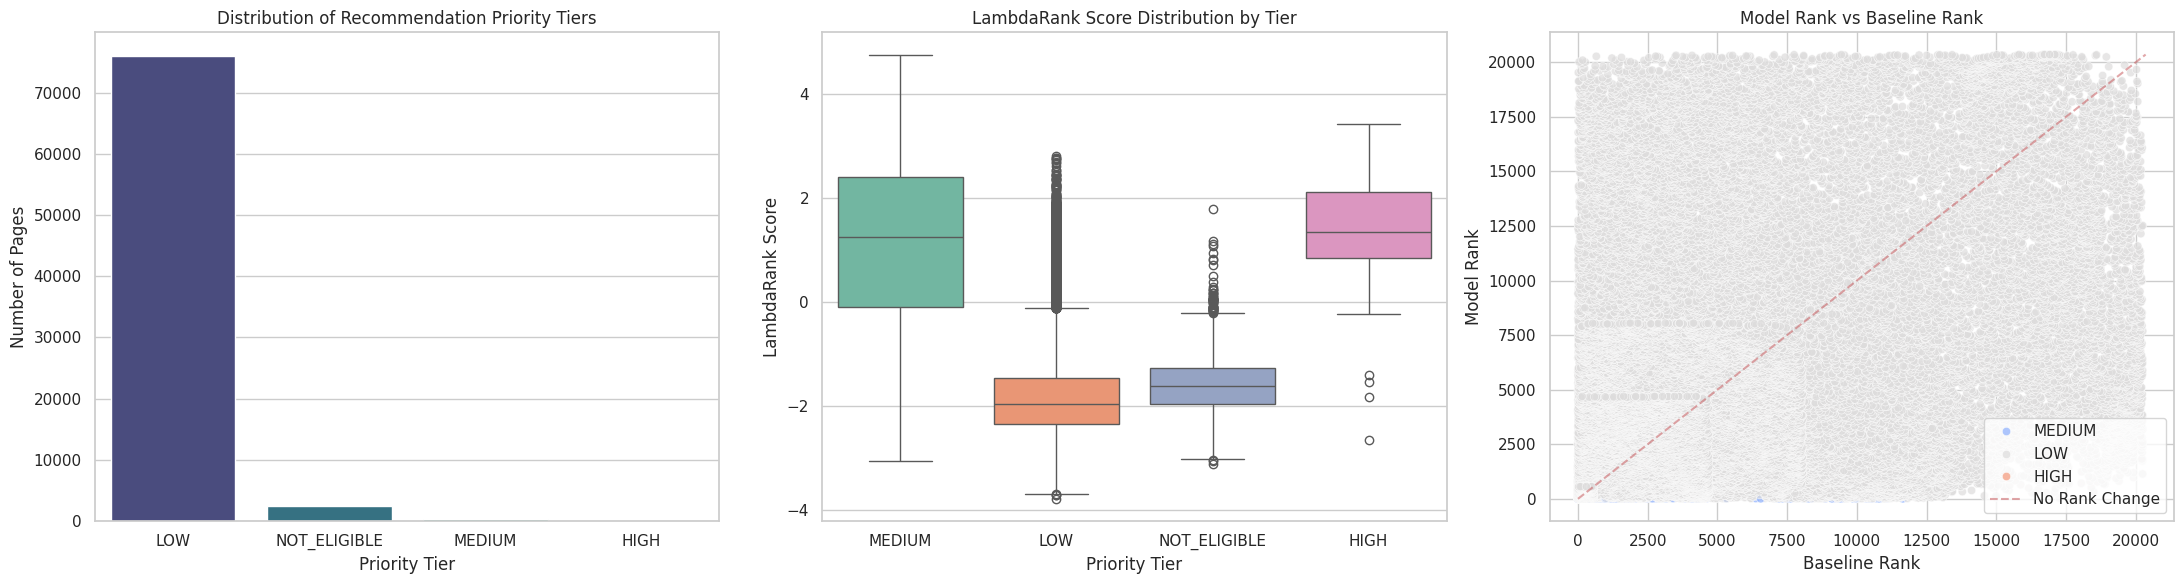

In [36]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set the visual style
sns.set_theme(style="whitegrid")

# Create a figure with multiple subplots
fig, axes = plt.subplots(1, 3, figsize=(22, 6))

# 1. Priority Tier Distribution
sns.barplot(data=tier_counts, x='priority_tier', y='rows', hue='priority_tier', palette='viridis', legend=False, ax=axes[0])
axes[0].set_title('Distribution of Recommendation Priority Tiers')
axes[0].set_ylabel('Number of Pages')
axes[0].set_xlabel('Priority Tier')

# 2. LambdaRank Score Distribution by Tier
sns.boxplot(data=stage4_snapshot, x='priority_tier', y='lambdarank_score', hue='priority_tier', palette='Set2', legend=False, ax=axes[1])
axes[1].set_title('LambdaRank Score Distribution by Tier')
axes[1].set_ylabel('LambdaRank Score')
axes[1].set_xlabel('Priority Tier')

# 3. Model Rank vs Baseline Rank for Actionable Tiers
actionable = stage4_snapshot[stage4_snapshot['priority_tier'].isin(['HIGH', 'MEDIUM', 'LOW'])]
if 'baseline_rank' in actionable.columns and 'model_rank' in actionable.columns:
    sns.scatterplot(data=actionable, x='baseline_rank', y='model_rank', hue='priority_tier', palette='coolwarm', alpha=0.7, ax=axes[2])
    # Add a diagonal line for reference
    max_rank = max(actionable['baseline_rank'].max(), actionable['model_rank'].max())
    axes[2].plot([0, max_rank], [0, max_rank], 'r--', alpha=0.5, label='No Rank Change')
    axes[2].set_title('Model Rank vs Baseline Rank')
    axes[2].set_xlabel('Baseline Rank')
    axes[2].set_ylabel('Model Rank')
    axes[2].legend()

plt.tight_layout()
plt.show()
